# **🚴‍♀️ Проект спринта: Нелинейные модели против сочинской погоды**

https://github.com/Konopatskaya/BikeSouth

Компания **BikeSochi**, оператор городского велопроката в Сочи, обратилась за помощью в улучшении системы прогнозирования почасового спроса на велосипеды.

До этого аналитики компании использовали простую линейную регрессию — одну из самых базовых моделей машинного обучения.

Однако её прогнозы часто ошибались:



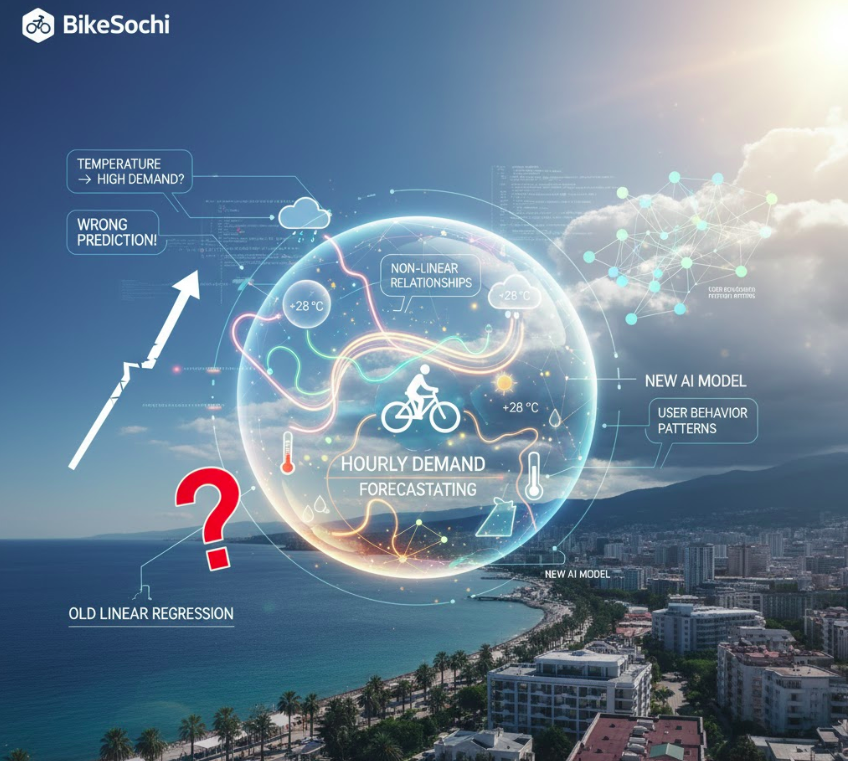

> «Модель видела, что температура выросла — и сразу предсказывала высокий спрос.
Но не понимала, что +28 °C под палящим солнцем и +28 °C после дождя — это две совсем разные ситуации.»

Погода в Сочи меняется быстро, и влияние факторов — нелинейное: температура, влажность, солнечная радиация, осадки влияют на поведение людей не по простым прямым зависимостям.



---



В рамках этого проекта вы выступаете в роли аналитиков компании **BikeSochi, которые должны предложить новую, более гибкую модель прогнозирования.**

**В этом проекте вы:**

1. Изучите предоставленную компанией baseline-модель (линейную регрессию);

2. Обучите новые модели — K-ближайших соседей (KNN) и решающее дерево (Decision Tree);

3. Проведёте подбор гиперпараметров с помощью библиотеки Optuna;

4. Сравните результаты всех подходов, выберете наилучший и аргументируете свой выбор.

Дополнительно: Реализуете собственный класс-трансформер и интегрируете его в пайплайн.


**К концу проекта у вас будет:**

— улучшенная модель прогноза почасового спроса на велосипеды в Сочи;

— отчёт с метриками и сравнением подходов;

— сохранённый пайплайн лучшей модели.



---



# **Часть 1: Базовая модель**

В этой части вы познакомитесь с тем, как работает baseline-модель, которую использовала компания BikeSochi до внедрения улучшенной версии.

Компания предоставила вам:

— baseline_linear_regression_pipeline.pkl — готовый обученный пайплайн (без исходного кода);

— краткое описание того, как он был устроен;

— тренировочную и тестовую выборки, которые можно использовать для оценки модели.

Это значит, что вам не нужно обучать эту модель заново — вы просто загружаете её и проверяете качество (например, на метриках RMSE, MAE, R²).

**Совет:**
1. Убедитесь, что у вас есть baseline_linear_regression_pipeline.pkl и train_data.csv и test_data.csv.

2. Разделите тестовый набор на признаки (X) и целевую переменную Rented Bike Count.

3. Загрузите .pkl файл — это готовый пайплайн, который сам обрабатывает данные и делает предсказания. Модель автоматически применяет трансформации и возвращает прогнозы.

4. Посчитайте RMSE, MAE и R², эти результаты нужны для оценки ваших улучшенных моделей в дальнейшей работе.

# **Часть 2: Улучшение модели — KNN и Decision Tree**

Ваша задача — предложить более гибкую модель прогноза спроса на велосипеды, которая учитывает нюансы сочинской погоды и поведение клиентов.

Вы будете экспериментировать с K-ближайшими соседями (KNN) и решающим деревом (Decision Tree), использовать подбор гиперпараметров с Optuna и внедрять кастомные трансформеры для новых признаков.

**Шаг 1: Изучение постановки задачи:**

Проведите EDA (Exploratory Data Analysis):
1. Посмотрите на распределение целевой переменной Rented Bike Count. Есть ли выбросы или сильные сезонные колебания?
2. Постройте графики зависимости спроса от температуры, осадков, солнечной радиации.
3. Сравните спрос в разные сезоны и праздничные дни.
4. Проверьте корреляции между признаками и целевой переменной.

**Совет:**

Не нужно сразу всё усложнять. Начните с базовых графиков и описательной статистики.



---



**Шаг 2: Разделение данных на тренировочную и валидационную выборки**

> У вас есть доступ к тренировочной и тестовой выборкам.

Тестовый набор используется для финальной оценки модели после тренировки и подбора гиперпараметров.

Вы тренируетесь на тренировочных данных и оцениваете качество через валидацию.

---



**Шаг 3: Обучение новых моделей**

> Теперь пора «проверить, насколько далеко уедут модели» — KNN и Decision Tree могут уловить нелинейные зависимости, недоступные линейной регрессии.

Что нужно сделать:
1. Подготовьте пайплайн для каждой модели:
    * Предобработка данных.
    * Модель (KNN или Decision Tree).
4. Настройте базовые параметры моделей (например, n_neighbors для KNN, max_depth для дерева).

**Совет:**

Начинайте с базовых параметров, чтобы убедиться, что пайплайн работает. Оптимизацию параметров делаем на следующем шаге.

---



**Шаг 4: Подбор гиперпараметров с Optuna**

> Компания хочет точную модель. Optuna поможет найти лучшие параметры для KNN и дерева, чтобы снизить ошибки прогноза.

Что нужно сделать:
1. Определите функцию цели для Optuna.

2. Настройте диапазоны гиперпараметров.

3. Запустите оптимизацию и сохраните лучшие параметры.

**Совет:**

Не бойтесь экспериментировать с небольшими диапазонами сначала, а потом расширять, если модель «не уловила» зависимости.

---



**Шаг 5: Кросс-валидация новых моделей**

Что нужно сделать:
1. Проведите кросс-валидацию для KNN и Decision Tree с оптимальными гиперпараметрами.
2. Сравните метрики с baseline-моделью.
3. Определите, какая модель показывает лучшие результаты на тренировочной выборке.

**Совет:**

Используйте визуализации (bar plot, box plot), чтобы увидеть разброс метрик и стабильность моделей.


---



**Шаг 6: Составление отчёта по моделям**

Что нужно сделать:
1. Составьте таблицу с метриками: baseline, KNN, Decision Tree.
2. Добавьте визуализацию, если необходимо: bar plot или box plot по RMSE/MAE.

Подготовьте выводы:
1. Какая модель лучше справляется с прогнозом?
2. Какие признаки, по вашему мнению, особенно важны?


**Совет:**

Старайтесь объяснить результаты в бизнес-контексте: «Эта модель лучше реагирует на дождь», «Температура и влажность сильно влияют на спрос в пиковые часы».

---



**Шаг 7: Сохранение модели и отчёта**

Что нужно сделать:
1. Выберите финальную, наилучшую модель и оцените её качество на тестовой выборке, чтобы понять, насколько она прогнозирует реальные данные.
2. Подготовьте ноутбук с кодом и комментариями: включите результаты всех экспериментов, метрики моделей, визуализации, а также обоснование выбора финальной модели.

**Совет:**

Документируйте каждый шаг: почему выбраны те или иные гиперпараметры и подходы. В реальной бизнес-задаче это помогает коллегам и руководству понимать решения и доверять модели.

---



**Опционально: Реализация кастомного трансформера**

> Простые признаки вроде температуры или влажности не всегда отражают реальную ситуацию.
Чтобы модель могла лучше прогнозировать спрос на велосипеды, можно создавать новые признаки, которые учитывают особенности погоды или взаимодействия факторов.

Что нужно сделать:
1. Реализуйте класс с методами fit и transform.
2. Вставьте его в пайплайн перед моделью.
3. Проверьте, что трансформер корректно работает с тренировочными данными.

**Совет:**
Если вы решите реализовать трансформер, начинайте с простых комбинаций признаков, чтобы не усложнять модель слишком рано.


---



# **Авторское решение**

##	Запуск предоставленного пайплайна с линейной регрессией

### Подготовка среды и библиотек

In [1]:
# !pip install -r requirements.txt

In [2]:
# Библиотеки для работы с данными и визуализации
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from phik import phik_matrix
import joblib
# Основная библиотека машинного обучения
import sklearn
import json
import optuna 
import eli5

# Классы из sklearn для разбиения данных и кросс-валидации
from sklearn.model_selection import train_test_split, KFold, cross_validate

# Классы для построения пайплайнов
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
#  для надежности установить опцию в sklearn, чтобы он всегда в пандас выводил
# Шаг 1: Импортируем функцию
from sklearn import set_config
# Шаг 2: Вызываем функцию для изменения глобальной настройки
set_config(transform_output="pandas")

# Трансформеры для предобработки данных
from sklearn.preprocessing import StandardScaler,OneHotEncoder, FunctionTransformer 
from sklearn.impute import SimpleImputer

# Модель для классификации
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score,  make_scorer
from sklearn.metrics import classification_report, confusion_matrix
#from sklearn.svm import LinearSVC
# Решающее дерево
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from IPython.display import display
from eli5.sklearn import PermutationImportance
from sklearn.model_selection import cross_val_score
from sklearn.base import BaseEstimator, TransformerMixin

**Константы**

In [3]:
RANDOM_SEED=42

Зафиксирую cv для моделей кросс-валидации

In [4]:
cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

### Загружаю датасет: ds_s14_train_data.csv

In [5]:
df=pd.read_csv('ds_s14_train_data.csv', decimal='.')

Познакомимся с датафреймом с помощью функции `show_df`.

Чтобы корректно работать с моделью, необходимо привести столбцы датафрейма к стилю Snake case, переименовать их также, как в модели на шаге `preprocessor`.

In [6]:
BOLD = '\033[1m'
RESET = '\033[0m'
def show_df(tmp0):
    tmp0.columns=tmp0.columns.str.lower()
    tmp0.columns = tmp0.columns.str.replace(" ", "_")

    display(tmp0.head())
    print('\n' + '='*50 + '\nИнформация о DataFrame:\n' + '='*50)
    tmp0.info()
    
    count_float = 0
    count_object=0
    count_int=0
    count_datetime=0
    count_bool=0
    list_fl=[]
    list_obj=[]
    list_int=[]
    list_dt=[]
    list_bool=[]
    for col in tmp0.columns:
        if tmp0[col].dtype in ['float16', 'float32', 'float64']:
            list_fl.append(col)
            count_float += 1
        if tmp0[col].dtype in ['object']:
            list_obj.append(col)
            count_object += 1
        if tmp0[col].dtype in ['int16', 'int32', 'int64']:
            list_int.append(col)
            count_int += 1
        if tmp0[col].dtype in ['datetime64[ns]']:
            list_dt.append(col)
            count_datetime += 1
        if tmp0[col].dtype in ['bool']:
            list_bool.append(col)
            count_bool += 1
        
    return print(f'\n Датафрейм содержит: строк - {BOLD}{tmp0.shape[0]}{RESET}, столбцов - {BOLD}{tmp0.shape[1]}{RESET} \n'
                 f'\n Названия столбцов датафрейма приведены к стилю {BOLD}snake case{RESET} \n'
                 f'\n Столбцов типа {BOLD}float{RESET}: {count_float} : {list_fl}\n' 
                 f'\n Столбцов типа {BOLD}object: {count_object}{RESET}\n : {list_obj}'
                 f'\n Столбцов типа {BOLD}int: {count_int}{RESET}\n : {list_int}'
                 f'\n Столбцов типа {BOLD}datetime: {count_datetime}{RESET} :{list_dt}'
                 f'\n Столбцов типа {BOLD}bool: {count_bool}{RESET} :{list_bool}'
                 )

show_df(df)

,temperature,humidity(%),wind_speed_(m/s),visibility_(10m),dew_point_temperature,solar_radiation_(mj/m2),rainfall(mm),snowfall_(cm),seasons,holiday,functioning_day,time_period_evening,time_period_late_evening,time_period_morning,time_period_night,rented_bike_count
0,20.3,35.0,2.4,2000.0,4.3,0.46,0.0,0.0,Autumn,Holiday,Yes,True,False,False,False,1237
1,25.4,55.0,3.2,2000.0,15.6,0.15,0.0,0.0,Autumn,No Holiday,Yes,True,False,False,False,2468
2,-6.9,39.0,1.6,2000.0,-18.5,0.00,0.0,0.0,Winter,No Holiday,Yes,False,True,False,False,186
3,-5.2,37.0,2.2,2000.0,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes,False,False,False,True,254
4,23.4,34.0,2.1,2000.0,6.6,2.84,0.0,0.0,Autumn,No Holiday,Yes,False,False,False,False,1686



Информация о DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               7008 non-null   float64
 1   humidity(%)               6758 non-null   float64
 2   wind_speed_(m/s)          6798 non-null   float64
 3   visibility_(10m)          6749 non-null   float64
 4   dew_point_temperature     7008 non-null   float64
 5   solar_radiation_(mj/m2)   6798 non-null   float64
 6   rainfall(mm)              6746 non-null   float64
 7   snowfall_(cm)             6745 non-null   float64
 8   seasons                   7008 non-null   object 
 9   holiday                   7008 non-null   object 
 10  functioning_day           7008 non-null   object 
 11  time_period_evening       7008 non-null   bool   
 12  time_period_late_evening  7008 non-null   bool   
 13  time_period_morning       7008 non-nul

- num:['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m', 'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm', 'snowfall_cm']
- cat: ['seasons', 'holiday', 'functioning_day']
- time: ['time_period_evening', 'time_period_late_evening', 'time_period_morning', 'time_period_night']

Переименуем столбцы в соответствии с шагом `preprocrssor`: 'humidity(%)', 'wind_speed_(m/s)', 'visibility_(10m)', 'solar_radiation_(mj/m2)', 'rainfall(mm)', 'snowfall_(cm)'


In [7]:
df.rename(columns={
    'humidity(%)': 'humidity',
    'wind_speed_(m/s)': 'wind_speed_ms',
    'visibility_(10m)': 'visibility_10m',
    'solar_radiation_(mj/m2)': 'solar_radiation_mjm2',
    'rainfall(mm)': 'rainfallmm',
    'snowfall_(cm)': 'snowfall_cm'
}, inplace=True)

In [8]:
df.columns

Index(['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count'],
      dtype='object')

Столбцы переименовали, теперь они правильно называются как в пайплайне 

### Загружаю датасет: ds_s14_test_data.csv

In [9]:
df_test=pd.read_csv('ds_s14_test_data.csv', decimal='.')

Знакомлюсь с датафреймом

In [10]:
show_df(df_test)

,temperature,humidity(%),wind_speed_(m/s),visibility_(10m),dew_point_temperature,solar_radiation_(mj/m2),rainfall(mm),snowfall_(cm),seasons,holiday,functioning_day,time_period_evening,time_period_late_evening,time_period_morning,time_period_night,rented_bike_count
0,6.7,48.0,0.8,817.0,-3.5,0.39,0.0,0.0,Winter,No Holiday,Yes,False,False,False,False,402
1,-5.3,90.0,1.1,311.0,-6.6,0.00,0.0,2.2,Winter,No Holiday,Yes,False,False,True,False,178
2,2.9,66.0,1.2,173.0,-2.8,0.00,0.0,0.0,Winter,No Holiday,Yes,False,True,False,False,219
3,23.1,63.0,2.6,949.0,15.6,1.68,0.0,0.0,Spring,No Holiday,Yes,False,False,False,False,949
4,23.3,43.0,1.2,1257.0,10.0,1.91,0.0,0.0,Summer,No Holiday,Yes,False,False,True,False,1005



Информация о DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1752 entries, 0 to 1751
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               1752 non-null   float64
 1   humidity(%)               1680 non-null   float64
 2   wind_speed_(m/s)          1700 non-null   float64
 3   visibility_(10m)          1680 non-null   float64
 4   dew_point_temperature     1752 non-null   float64
 5   solar_radiation_(mj/m2)   1700 non-null   float64
 6   rainfall(mm)              1688 non-null   float64
 7   snowfall_(cm)             1691 non-null   float64
 8   seasons                   1752 non-null   object 
 9   holiday                   1752 non-null   object 
 10  functioning_day           1752 non-null   object 
 11  time_period_evening       1752 non-null   bool   
 12  time_period_late_evening  1752 non-null   bool   
 13  time_period_morning       1752 non-nul

Тоже переименуем столбцы

In [11]:
df_test.rename(columns={
    'humidity(%)': 'humidity',
    'wind_speed_(m/s)': 'wind_speed_ms',
    'visibility_(10m)': 'visibility_10m',
    'solar_radiation_(mj/m2)': 'solar_radiation_mjm2',
    'rainfall(mm)': 'rainfallmm',
    'snowfall_(cm)': 'snowfall_cm'
}, inplace=True)

In [12]:
df_test.columns

Index(['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count'],
      dtype='object')

In [13]:
df_test['holiday']=np.where(df_test['holiday']=='Holiday', 1, 0)

In [14]:
df_test['functioning_day']=np.where(df_test['functioning_day']=='Yes', 1, 0)

### Разобьём df_test на X_test и y_test

In [15]:
X_test=df_test.drop('rented_bike_count', axis=1)

In [16]:
y_test=df_test['rented_bike_count']

In [17]:
display(X_test.shape, y_test.shape)

(1752, 15)

(1752,)

Подготовили тестовые выборки

### Загружаю и изучаю модель 

In [18]:
model= joblib.load('baseline_linear_regression_pipeline.joblib')

Сразу модель не заработала. Ошибка: не соответствие названий столбцов.

Чтобы переименовать столбцы датафрейма так же, как в модели, посмотрим на шаги пайплайна

In [19]:
display(model.named_steps)

{'preprocessor': ColumnTransformer(transformers=[('num',
                                  Pipeline(steps=[('imputer',
                                                   SimpleImputer(strategy='median')),
                                                  ('scaler', StandardScaler())]),
                                  ['temperature', 'humidity', 'wind_speed_ms',
                                   'visibility_10m', 'dew_point_temperature',
                                   'solar_radiation_mjm2', 'rainfallmm',
                                   'snowfall_cm']),
                                 ('cat',
                                  Pipeline(steps=[('imputer',
                                                   SimpleImputer(strategy='most_frequent')),
                                                  ('onehot',
                                                   OneHotEncoder(handle_unknown='ignore',
                                                                 sparse_output=False

Теперь на этапе 2 исследования переименовыаваю столбцы

**Изучаю показатели качества модели `model`: оцениваю значения метрик RMSE, R² и MAE на обучающей выборке**

In [20]:
X0=df.drop('rented_bike_count', axis=1)
y0=df['rented_bike_count']

In [21]:
metrics={
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

scores_model = cross_validate(
    model,
    X0,
    y0,
    cv=cv, 
    scoring=metrics,
    return_train_score=True, 
    n_jobs=-1 
)

In [22]:
mean_rmse = np.mean(scores_model['test_RMSE'])
std_rmse=np.std(scores_model['test_RMSE'])

mean_mae = np.mean(scores_model['test_MAE'])
std_mae=np.std(scores_model['test_MAE'])

mean_r2 = np.mean(scores_model['test_R2'])
std_r2=np.std(scores_model['test_R2'])

display(f'RMSE: {mean_rmse:.4f} (+/- {std_rmse:.4f})') 
display(f'MAE: {mean_mae:.4f} (+/- {std_mae:.4f})') 
display(f'R2: {mean_r2:.4f} (+/- {std_r2:.4f})')

'RMSE: -413.9009 (+/- 3.1444)'

'MAE: -310.0915 (+/- 2.3415)'

'R2: 0.5894 (+/- 0.0102)'

Создам словарь с метриками для отчёта, п.6.

In [23]:
metric_name_model0 = {
    'RMSE': mean_rmse.round(3),
    'MAE': mean_mae.round(3),
    'R2': mean_r2.round(3)
}

In [24]:
display(metric_name_model0)

{'RMSE': np.float64(-413.901),
 'MAE': np.float64(-310.092),
 'R2': np.float64(0.589)}

**Изучаю показатели качества модели `model`: оцениваю значения метрик RMSE, R² и MAE на тестовой выборке**

также через кросс-валидацию для сапоставимости результатов

In [25]:
metrics={
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

scores_model = cross_validate(
    model,
    X_test,
    y_test,
    cv=cv, 
    scoring=metrics,
    return_train_score=True, 
    n_jobs=-1 
)

In [26]:
mean_rmse = np.mean(scores_model['test_RMSE'])
std_rmse=np.std(scores_model['test_RMSE'])

mean_mae = np.mean(scores_model['test_MAE'])
std_mae=np.std(scores_model['test_MAE'])

mean_r2 = np.mean(scores_model['test_R2'])
std_r2=np.std(scores_model['test_R2'])

display(f'RMSE: {mean_rmse:.4f} (+/- {std_rmse:.4f})') 
display(f'MAE: {mean_mae:.4f} (+/- {std_mae:.4f})') 
display(f'R2: {mean_r2:.4f} (+/- {std_r2:.4f})')

'RMSE: -412.1889 (+/- 4.4216)'

'MAE: -311.4121 (+/- 6.8902)'

'R2: 0.5824 (+/- 0.0262)'

Метрики на обучающей и тестовой выборках практически совпадают, значит модель не переобучена.

Сами метрики не высокие, есть что улучшить.
- R2 на уровне 0,58. То есть доля объясненной дисперсии только 58%. Модель работает чуть лучше простого угадывания.
- метрики MAE (средняя абсолютная ошибка) и RMSE (возведение разности в квадрат) достаточно большие, что соответствует низкому уровню R2. Отметим, что RMSE больше, значит в данных есть отклонения (ошибки) за которые она штрафует сильнее.

##	Подготовка и исследование данных

1. Преобразуем стоблцы в числовые: `holiday,  functioning_day,  time_period_evening,  time_period_late_evening,  time_period_morning, time_period_night`  

2. исследуем датафрейм **df** на пропуски, уникальные значения

3. создадим новые признаки

### Меняем в поле:

    - `holiday` значения **Holiday, No** на **1** и **0** соответственно
    - `functioning_day`значения **Yes, No** на **1** и **0** соответственно
    -  `time_period_evening,  time_period_late_evening,  time_period_morning, time_period_night` меняем тип с bool на int

In [27]:
df['holiday']=np.where(df['holiday']=='Holiday', 1, 0)

In [28]:
df['functioning_day']=np.where(df['functioning_day']=='Yes', 1, 0)

change_col=['time_period_evening', 'time_period_late_evening', 'time_period_morning', 'time_period_night']

for col in change_col:
    df[change_col]=df[change_col].astype(int)

Понизим разрядность полей в датафрейме

In [29]:
num_columns_int=df.select_dtypes(include=['integer']).columns.tolist()
for col in num_columns_int:
    df[col]=pd.to_numeric(df[col], downcast='integer')

num_columns_float=df.select_dtypes(include=['float']).columns.tolist()
for col in num_columns_float:
    df[col]=pd.to_numeric(df[col], downcast='float')


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               7008 non-null   float32
 1   humidity                  6758 non-null   float32
 2   wind_speed_ms             6798 non-null   float32
 3   visibility_10m            6749 non-null   float32
 4   dew_point_temperature     7008 non-null   float32
 5   solar_radiation_mjm2      6798 non-null   float32
 6   rainfallmm                6746 non-null   float32
 7   snowfall_cm               6745 non-null   float32
 8   seasons                   7008 non-null   object 
 9   holiday                   7008 non-null   int8   
 10  functioning_day           7008 non-null   int8   
 11  time_period_evening       7008 non-null   bool   
 12  time_period_late_evening  7008 non-null   bool   
 13  time_period_morning       7008 non-null   bool   
 14  time_per

### Обработка пропущенных значений

In [31]:
def show_missing_stats(tmp0):
    """
    Функция для отображения статистики пропущенных значений в DataFrame.
    """
    missing_stats = pd.DataFrame({
        'Кол-во пропусков': tmp0.isnull().sum(),
        'Доля пропусков': tmp0.isnull().mean()
    })
    missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
    
    if missing_stats.empty:
        return "Пропусков в данных нет"
    
    # Форматируем при выводе через Styler
    return (missing_stats.style.format({'Доля пропусков': '{:.4f}'}).background_gradient(cmap='coolwarm'))
show_missing_stats(df)

,Кол-во пропусков,Доля пропусков
humidity,250,0.0357
wind_speed_ms,210,0.0300
visibility_10m,259,0.0370
solar_radiation_mjm2,210,0.0300
rainfallmm,262,0.0374
snowfall_cm,263,0.0375


Для моделей kNN и дерево решений рекомендуется пропуски заполнять в пайплайне специальным значением -999999, тогда информация о пропусках тоже может дать модели какую-то полезную информацию.

В нашем датафрейме пропусков не много, меньше процента, по 250 записей. Поэтому в данном случае, всё-таки заменю в пайплайне на среднее значение.

### Проверка на дубликаты

In [32]:
def obvious_duplicates(tmp0):
    """
    Функция для удаления явных дубликатов.
    """
    # Отсортируем датафрейм по всем столбцам
    df_sorted = tmp0.sort_values(by=tmp0.columns.tolist())
    # Находим дубликаты
    duplicates = df_sorted[df_sorted.duplicated(keep=False)]

    df_no_duplicated = df_sorted.drop_duplicates()
    display(f'Удалено явных дубликатов: {duplicates.shape[0]}, Число строк в датафрейме: {df_no_duplicated.shape[0]}')
    return df_no_duplicated

In [33]:
df=obvious_duplicates(df)

df.shape

'Удалено явных дубликатов: 0, Число строк в датафрейме: 7008'

(7008, 16)

Проверим на неявные дубликаты по полям: 'temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day'

In [34]:
def implicit_duplicates(values):
    
    df_sorted3=df.sort_values(by=df.columns.tolist())
     
    df_no_duplicated3=df_sorted3.drop_duplicates(subset=values)
    count_df_no_duplicated3=df.shape[0]-df_no_duplicated3.shape[0]
    display(f'Удалено неявных дубликатов по столбцам {values}: {count_df_no_duplicated3}')
    procent=round(1-df_no_duplicated3.shape[0]/len(df_sorted3), 3)
    print(f'доля неявных дубликатов в датафрейме {procent} ')    


In [35]:
implicit_duplicates(['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m', 
                     'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm', 
                     'snowfall_cm', 'holiday', 'functioning_day'])

"Удалено неявных дубликатов по столбцам ['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m', 'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm', 'snowfall_cm', 'holiday', 'functioning_day']: 1"

доля неявных дубликатов в датафрейме 0.0 


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7008 entries, 3056 to 2749
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               7008 non-null   float32
 1   humidity                  6758 non-null   float32
 2   wind_speed_ms             6798 non-null   float32
 3   visibility_10m            6749 non-null   float32
 4   dew_point_temperature     7008 non-null   float32
 5   solar_radiation_mjm2      6798 non-null   float32
 6   rainfallmm                6746 non-null   float32
 7   snowfall_cm               6745 non-null   float32
 8   seasons                   7008 non-null   object 
 9   holiday                   7008 non-null   int8   
 10  functioning_day           7008 non-null   int8   
 11  time_period_evening       7008 non-null   bool   
 12  time_period_late_evening  7008 non-null   bool   
 13  time_period_morning       7008 non-null   bool   
 14  time_perio

In [37]:
df.columns

Index(['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count'],
      dtype='object')

### Исследуем категориальные признаки

Исследуем категориальные признаки: `'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'is_holiday', 'is_no_holiday', 'is_functioning_day',
       'is_no_functioning_day', 'season_sin', 'season_cos'`

In [38]:
def feature_category (tmp0, value):
    '''
    Исследует категориальные (числовые) признаки по столбцам:
      Считает описательные статистики
      столбчатые диаграммы по столвцам/столбцу
    
    value - столбцы/столбец
    
    '''
    BOLD = '\033[1m' 
    RESET = '\033[0m'
    
    for col in value:
        print(f'Описательные статистики для столбца {BOLD} {col} {RESET}:')  
        print(tmp0[col].describe())
        sns.set_theme(style="darkgrid")
        tmp0[col].value_counts().plot(
            kind='bar',
            edgecolor='black',
            rot=0 
        )

        plt.title(col, fontsize=14)
        plt.xlabel(col, fontsize=12)
        plt.ylabel('Частота', fontsize=12)

        plt.tight_layout()
        plt.show()


Описательные статистики для столбца  seasons :
count       7008
unique         4
top       Autumn
freq        1770
Name: seasons, dtype: object


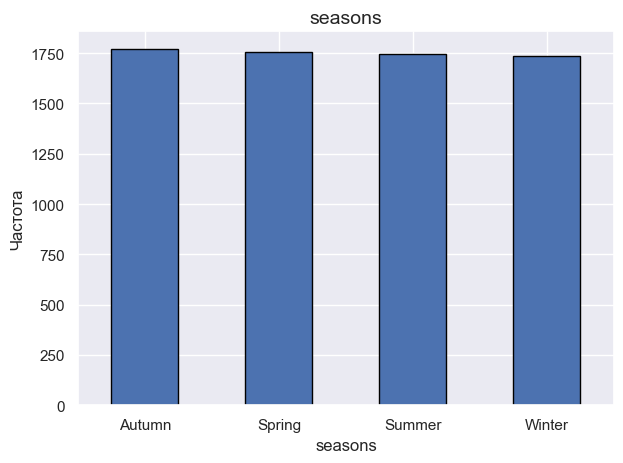

Описательные статистики для столбца  holiday :
count    7008.000000
mean        0.048516
std         0.214869
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: holiday, dtype: float64


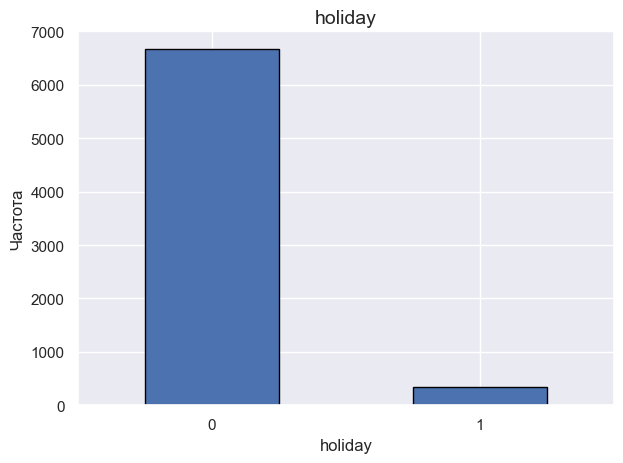

Описательные статистики для столбца  functioning_day :
count    7008.000000
mean        0.965468
std         0.182604
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: functioning_day, dtype: float64


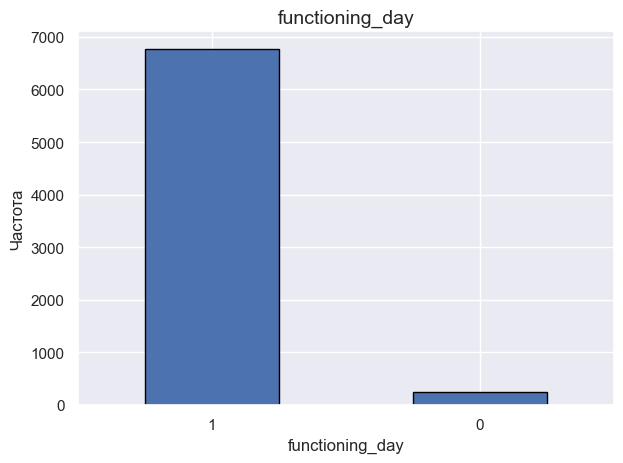

Описательные статистики для столбца  time_period_evening :
count      7008
unique        2
top       False
freq       5840
Name: time_period_evening, dtype: object


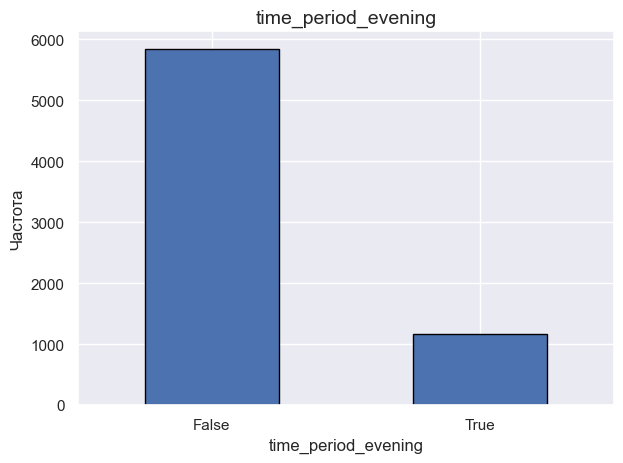

Описательные статистики для столбца  time_period_late_evening :
count      7008
unique        2
top       False
freq       5835
Name: time_period_late_evening, dtype: object


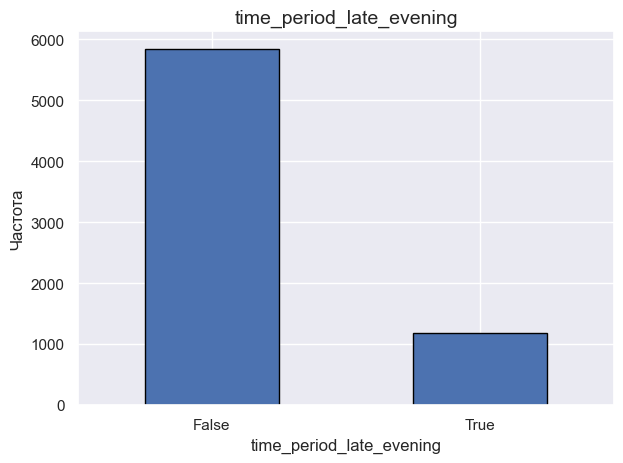

Описательные статистики для столбца  time_period_morning :
count      7008
unique        2
top       False
freq       5836
Name: time_period_morning, dtype: object


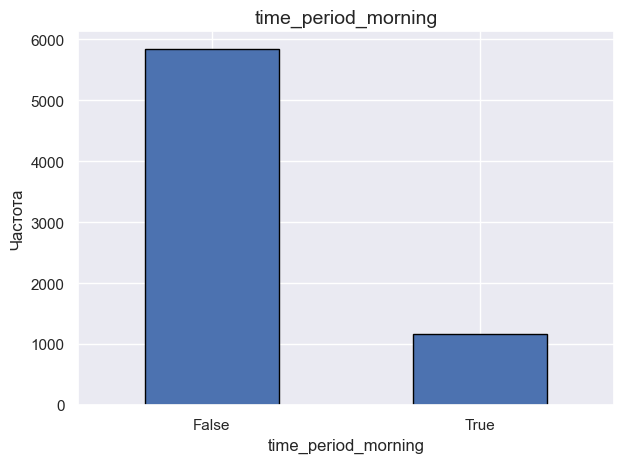

Описательные статистики для столбца  time_period_night :
count      7008
unique        2
top       False
freq       5255
Name: time_period_night, dtype: object


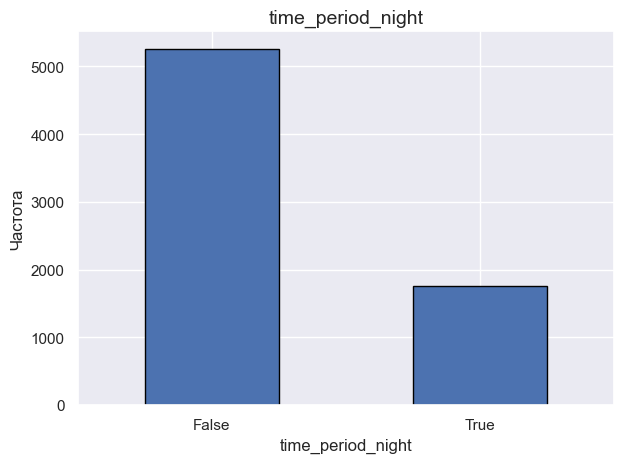

In [39]:
feature_category (df, ['seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night' ])

Распределение в долях категориальной `seasons` по бинарным признакам

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7008 entries, 3056 to 2749
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               7008 non-null   float32
 1   humidity                  6758 non-null   float32
 2   wind_speed_ms             6798 non-null   float32
 3   visibility_10m            6749 non-null   float32
 4   dew_point_temperature     7008 non-null   float32
 5   solar_radiation_mjm2      6798 non-null   float32
 6   rainfallmm                6746 non-null   float32
 7   snowfall_cm               6745 non-null   float32
 8   seasons                   7008 non-null   object 
 9   holiday                   7008 non-null   int8   
 10  functioning_day           7008 non-null   int8   
 11  time_period_evening       7008 non-null   bool   
 12  time_period_late_evening  7008 non-null   bool   
 13  time_period_morning       7008 non-null   bool   
 14  time_perio

In [41]:
def explorer_cat(tmp0, churn, value, title_churn):
    """
    Функция работает с категориальными столбцами.
    Строит таблицу по признакам категории, считает их долю и количество по убыванию.
    Отображает на столбчатой диаграмме: ось X — распределение признаков категориальной переменной,
    ось Y — доля бинарного признака (например, churn), распределение которого смотрим по категориальным столбцам.

    Параметры:
    tmp0 — датафрейм
    churn — бинарный признак, распределение которого смотрим
    value — список категориальных столбцов
    title_churn — заголовок для графиков
    """

    for col in value:
        # Группируем по категориальному столбцу, считаем среднее и количество
        grouped = tmp0.groupby(col)
        share = grouped[churn].agg(['mean', 'count'])

        # Фильтруем записи с малым числом пользователей и сортируем
        sorted_share = share[share['count'] > 100].sort_values('mean', ascending=False)

        print(f"\n{'=' * 60}")
        print(f"{title_churn} {col}:")
        print('=' * 60)
        print(sorted_share)

        n_categories = len(sorted_share.index)

        if n_categories < 10:
            # Вертикальная столбчатая диаграмма
            plt.figure(figsize=(8, 4))
            sorted_share['mean'].plot(
                kind='bar',
                rot=0,
                legend=False,
                title=f'{col}'
            )
            plt.axhline(tmp0[churn].mean(), color='red', linestyle='--', linewidth=1,
                       label=f'среднее {churn}: {round(tmp0[churn].mean(), 4)}')
            plt.xlabel(col)
            plt.ylabel(title_churn)

        else:
            # Горизонтальная столбчатая диаграмма (первые 10 категорий)
            plt.figure(figsize=(8, 6))
            sorted_share['mean'].head(10).plot(
                kind='barh',
                rot=0,
                legend=False,
                title=f'{col} (топ-10 по доле {title_churn})'
            )
            plt.axvline(tmp0[churn].mean(), color='red', linestyle='--', linewidth=1,
                     label=f'среднее {churn}: {round(tmp0[churn].mean(), 4)}')
            plt.xlabel('Доля ' + title_churn)
            plt.ylabel(col)

        plt.grid()
        plt.legend()
        plt.show()



holiday seasons:
             mean  count
seasons                 
Winter   0.086982   1736
Autumn   0.050847   1770
Spring   0.033561   1758
Summer   0.022936   1744


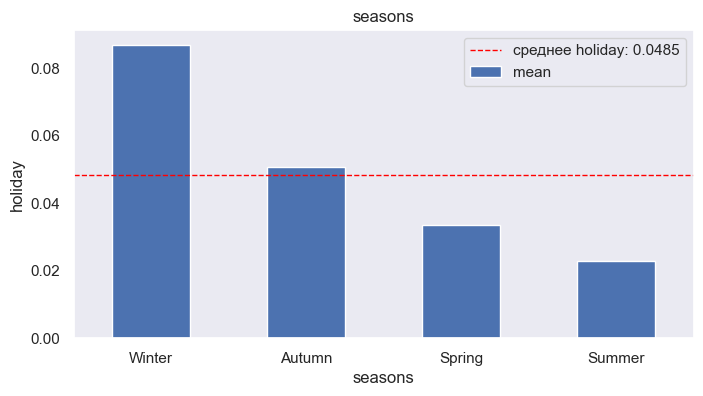

In [42]:
explorer_cat(
    df,
    'holiday',
    ['seasons'],
    'holiday')


functioning_day seasons:
             mean  count
seasons                 
Winter   1.000000   1736
Summer   1.000000   1744
Spring   0.976678   1758
Autumn   0.886441   1770


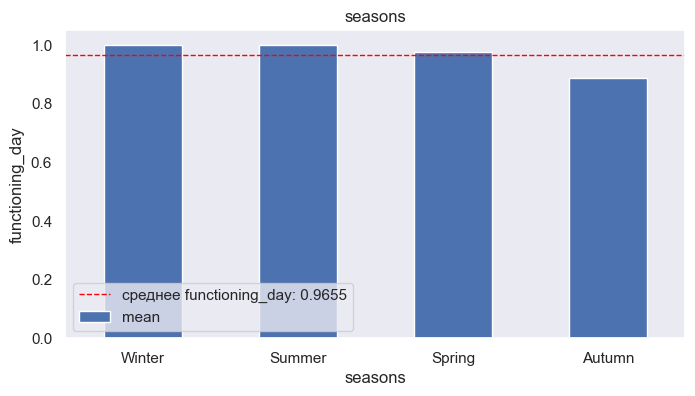

In [43]:
explorer_cat(
    df,
    'functioning_day',
    ['seasons'],
    'functioning_day')


time_period_evening seasons:
             mean  count
seasons                 
Summer   0.169725   1744
Autumn   0.166102   1770
Winter   0.165899   1736
Spring   0.164960   1758


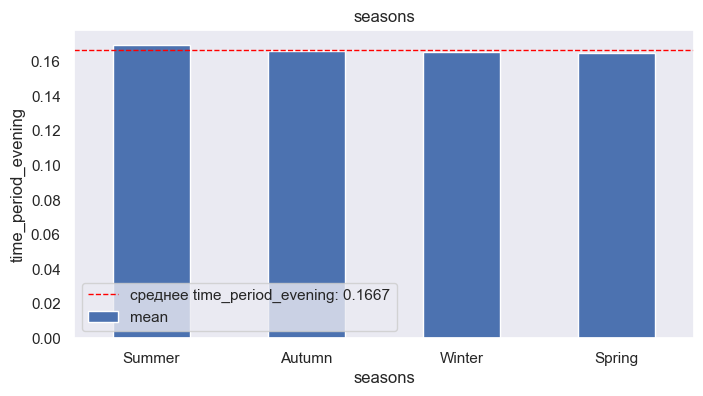

In [44]:
explorer_cat(
    df,
    'time_period_evening',
    ['seasons'],
    'time_period_evening')


time_period_late_evening seasons:
             mean  count
seasons                 
Autumn   0.169492   1770
Winter   0.167051   1736
Summer   0.166858   1744
Spring   0.166098   1758


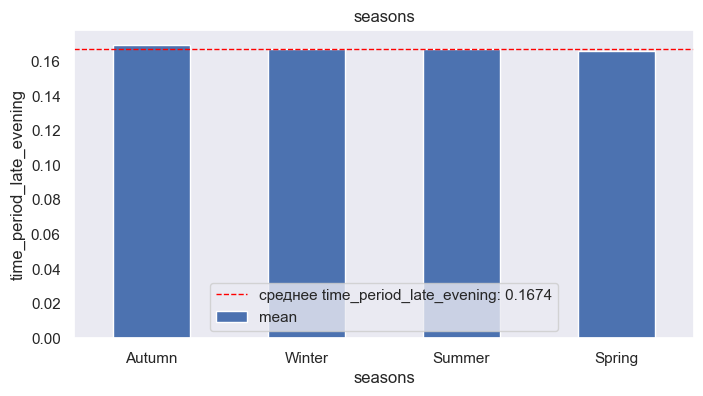

In [45]:
explorer_cat(
    df,
    'time_period_late_evening',
    ['seasons'],
    'time_period_late_evening')


time_period_morning seasons:
             mean  count
seasons                 
Autumn   0.168927   1770
Spring   0.167804   1758
Summer   0.166284   1744
Winter   0.165899   1736


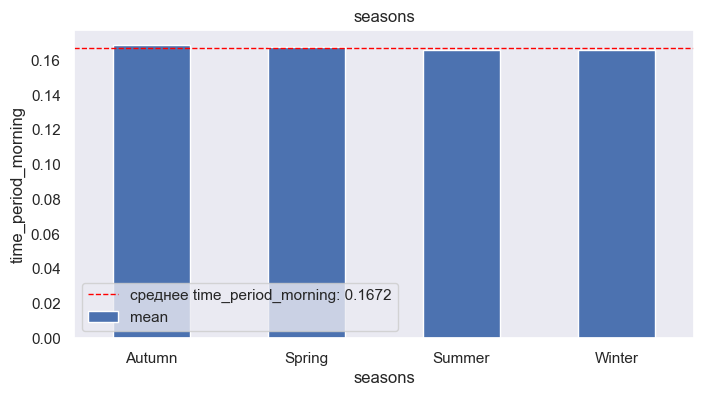

In [46]:
explorer_cat(
    df,
    'time_period_morning',
    ['seasons'],
    'time_period_morning')


time_period_night seasons:
             mean  count
seasons                 
Winter   0.251152   1736
Summer   0.250000   1744
Autumn   0.249718   1770
Spring   0.249716   1758


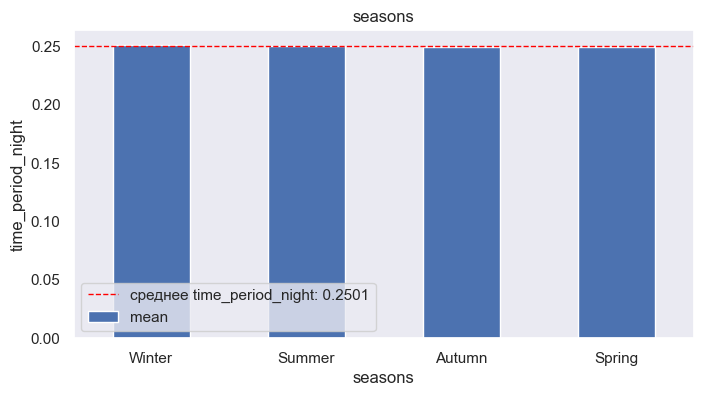

In [47]:
explorer_cat(
    df,
    'time_period_night',
    ['seasons'],
    'time_period_night')

Распределение в долях категориальной seasons по бинарным признакам показало, что:

- в выходные чаще арендуют зимой (лидер), и осенью. Наблюдается зависимость от времен года
- в рабочее время аренда велосипедов чаще зимой и летом. Слабая зависимость.
- по пременным интервалам и сезонам зависимости нет

In [48]:
df.columns

Index(['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count'],
      dtype='object')

### Исследуем числовые непрерывные признаки

In [49]:
def feature_distribution (value):
    '''
    Исследует распределение признаков по столбцам:
      Считает описательные статистики
      Строит гистограммы распределения, ящики с усами по столвцам/столбцу
    
    value - столбцы/столбец
    
    '''
    BOLD = '\033[1m' 
    RESET = '\033[0m'
    
    for col in value:
        print(f'Описательные статистики для столбца {BOLD} {col} {RESET}:')  
        print(df[col].describe())
        sns.set_theme(style="darkgrid")
        
        f, (ax_box, ax_hist) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.15, .85)})
      
        sns.boxplot(data=df, x=col, orient="h", ax=ax_box)  # Явно указываем data и x
        sns.histplot(data=df, x=col, ax=ax_hist, bins=50, edgecolor='black')
        
        ax_box.set(xlabel='')
        plt.show()

Описательные статистики для столбца  temperature :
count    7008.000000
mean       12.812913
std        11.924631
min       -17.500000
25%         3.300000
50%        13.500000
75%        22.400000
max        39.400002
Name: temperature, dtype: float64


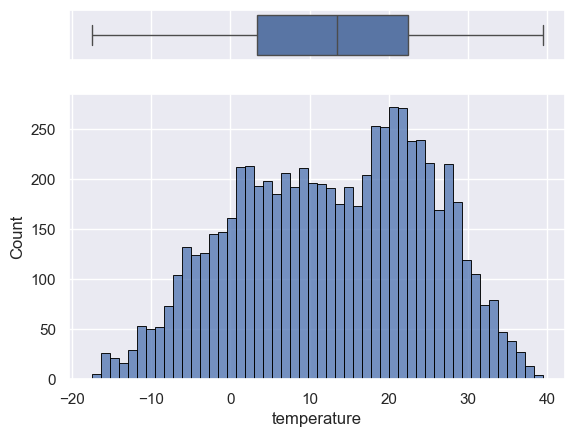

Описательные статистики для столбца  humidity :
count    6758.000000
mean       58.200504
std        20.340298
min         0.000000
25%        42.000000
50%        57.000000
75%        74.000000
max        98.000000
Name: humidity, dtype: float64


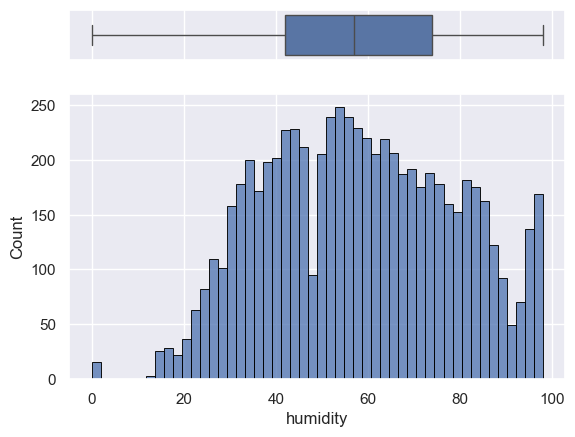

Описательные статистики для столбца  wind_speed_ms :
count    6798.000000
mean        1.725228
std         1.042957
min         0.000000
25%         0.900000
50%         1.500000
75%         2.300000
max         7.400000
Name: wind_speed_ms, dtype: float64


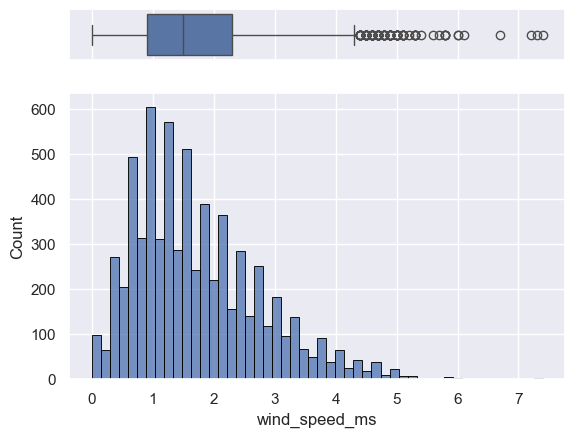

Описательные статистики для столбца  visibility_10m :
count    6749.000000
mean     1435.156738
std       607.292480
min        27.000000
25%       936.000000
50%      1691.000000
75%      2000.000000
max      2000.000000
Name: visibility_10m, dtype: float64


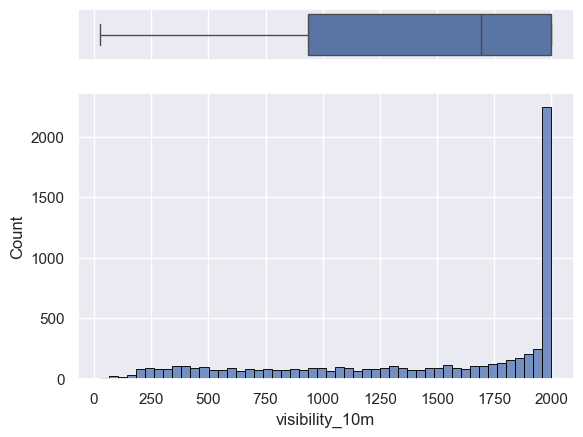

Описательные статистики для столбца  dew_point_temperature :
count    7008.000000
mean        4.021490
std        13.033395
min       -30.600000
25%        -4.700000
50%         5.000000
75%        14.800000
max        26.799999
Name: dew_point_temperature, dtype: float64


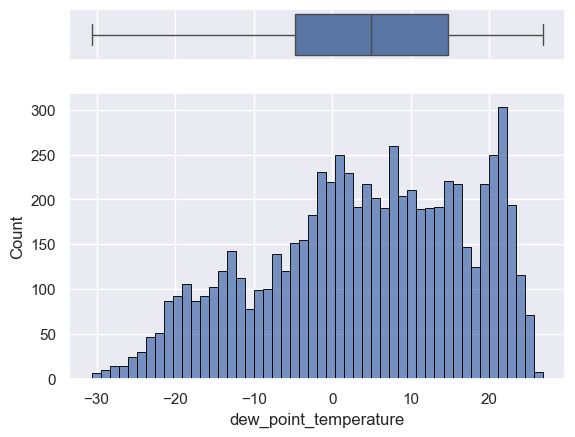

Описательные статистики для столбца  solar_radiation_mjm2 :
count    6798.000000
mean        0.569885
std         0.866140
min         0.000000
25%         0.000000
50%         0.010000
75%         0.940000
max         3.520000
Name: solar_radiation_mjm2, dtype: float64


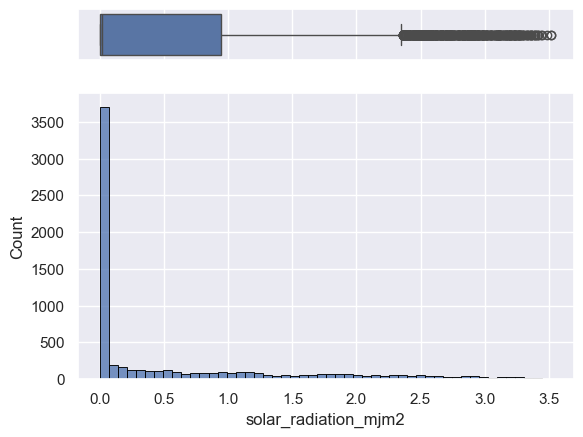

Описательные статистики для столбца  rainfallmm :
count    6746.000000
mean        0.146902
std         1.164101
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        35.000000
Name: rainfallmm, dtype: float64


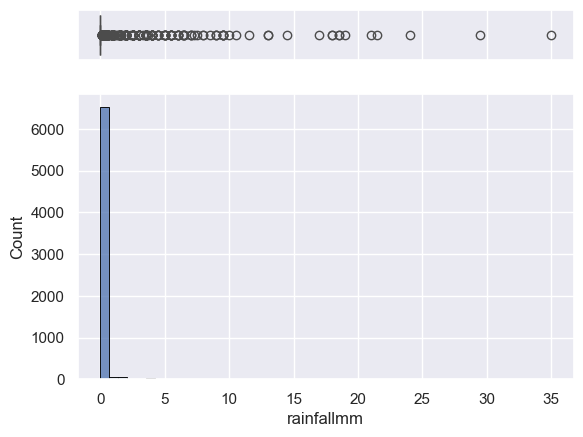

Описательные статистики для столбца  snowfall_cm :
count    6745.000000
mean        0.074752
std         0.438214
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         8.800000
Name: snowfall_cm, dtype: float64


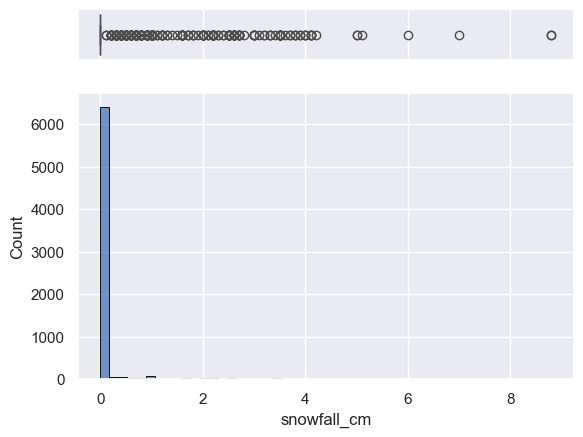

Описательные статистики для столбца  rented_bike_count :
count    7008.000000
mean      705.606022
std       646.311790
min         0.000000
25%       190.750000
50%       504.500000
75%      1070.000000
max      3556.000000
Name: rented_bike_count, dtype: float64


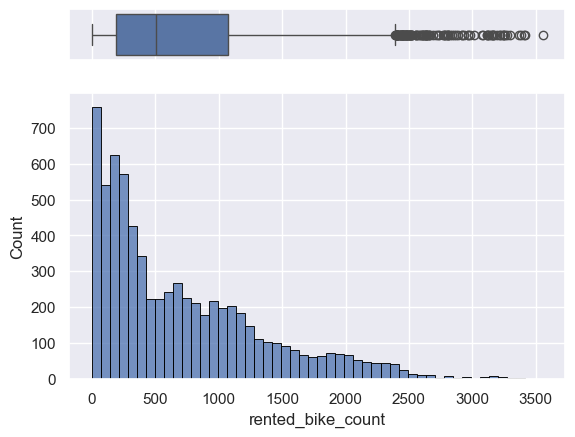

In [50]:
feature_distribution (['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'rented_bike_count'
       ])

- temperature -  от -17 до 39, близко к нормальному
- humidity - правостороннее, выбросы. Максимальное значение 7,4. - это нормально, не считаем выбросом
- wind_speed_ms - левостороннее, выбросов нет - 2000м/с (частота более 2000 )
- dew_point_temperature - близко к норм, левостор, выбросов нет
- solar_radiation_mjm2 = правосторонее, выбросы
- rainfallmm - есть выбросы
- snowfall_cm - есть выбросы
- rented_bike_count - Основная часть значений (75%) находится в пределах до 1070 велосипедов в день. Среднее значение не совпадает с медианой, есть выбросы, график "волнистый", значит возможны сезонные колебания
- wather_autumn - wather_winter -  выбросы
- osadki_autumn - osadki_winter - выбросы

**Есть выбросы, но модели kNN и дерево решений не чувствительны к ним, поэтому предобратоткой их заниматься не будем**

### Изучим распределение целевой переменной Rented Bike Count

#### 1. Посмотрите на распределение целевой переменной Rented Bike Count. Есть ли выбросы или сильные сезонные колебания?

- Основная часть значений (75%) находится в пределах до 1070 велосипедов в день. Правостороннее распределение. Среднее значение не совпадает с медианой, есть выбросы, график "волнистый", значит возможны сезонные колебания.

  

#### 2. Постройте графики зависимости спроса от температуры, осадков, солнечной радиации.

Признаки `'temperature', 'rainfallmm', 'snowfall_cm', 'wind_speed_ms', 'solar_radiation_mjm2'` - непрерывные признаки. Поэтому оптимальнее зависимости между ними и 'rented_bike_count' (тоже непрерывный признак) отобразить в виде диаграмм рассеяния

In [51]:
def scatter_and_line(tmp0, col1, col2, title):
    '''
    Рисует диаграмму рассеяния и ЛИНИЯ ТРЕНДА
    tmp0 - датафрейм 
    col1, col2 - непрерывные признакт 
    title - заголовок
    '''
    sns.regplot(
        data=tmp0,
        x=col1, 
        y=col2,
        scatter_kws={
            's': 30, 
            'color': 'darkorange', 
            'edgecolor': 'black', 
            'alpha': 0.8
        },
        line_kws={'color': 'red', 'linewidth': 2}
    )

    plt.title(title)
    plt.show()


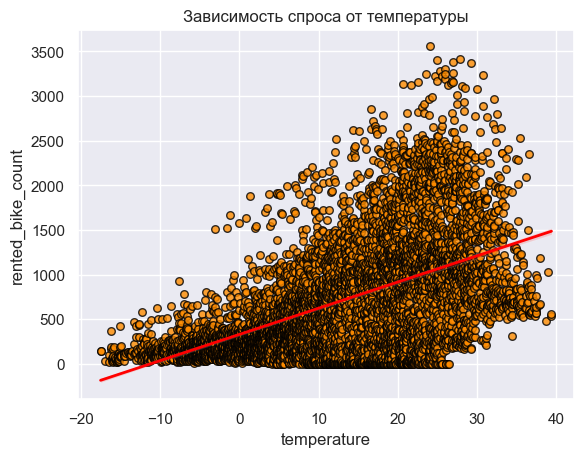

In [52]:
scatter_and_line(df, 'temperature', 'rented_bike_count', 'Зависимость спроса от температуры')

Строим диаграммы для остальных признаков: 'rainfallmm', 'snowfall_cm', 'wind_speed_ms', 'solar_radiation_mjm2'

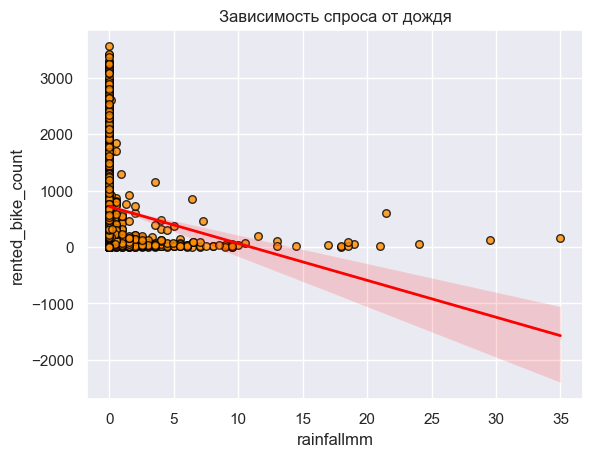

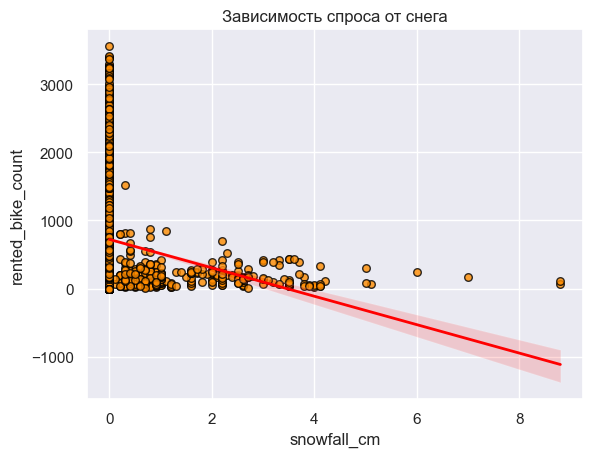

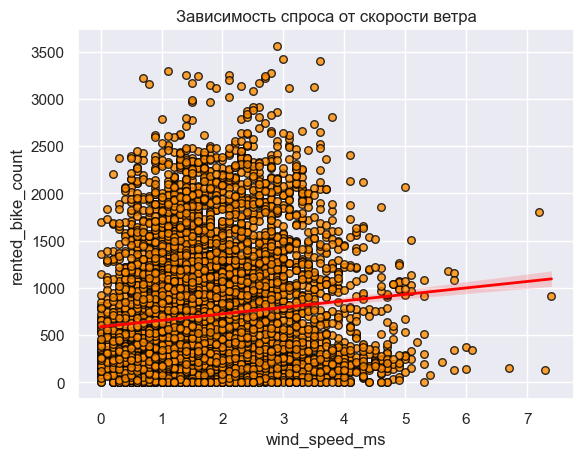

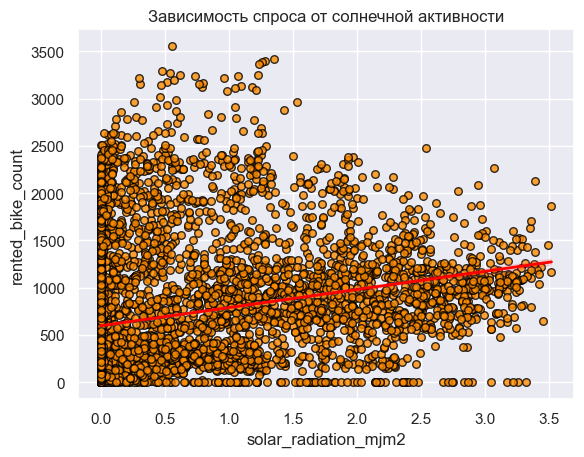

In [53]:
scatter_and_line(df, 'rainfallmm', 'rented_bike_count', 'Зависимость спроса от дождя')
scatter_and_line(df, 'snowfall_cm', 'rented_bike_count', 'Зависимость спроса от снега')
scatter_and_line(df, 'wind_speed_ms', 'rented_bike_count', 'Зависимость спроса от скорости ветра')
scatter_and_line(df, 'solar_radiation_mjm2', 'rented_bike_count', 'Зависимость спроса от солнечной активности')

Анализируя диаграммы рассеяния, сделали вывод:
- умеренная прямая зависимость спроса от температуры
- слабая обратная зависимость от снега
- более слабая обратная зависимость от дождя
- умеренная зависимость от солнечной активности
- от ветра зависимости нет (практически круг точек)

Таким образом, хорошие зависимости rented_bike_count от temperature и solar_radiation_mjm2, более слабые обратные от snowfall_cm и  rainfallmm.

#### Сравните спрос в разные сезоны и праздничные дни

Изучаем спрос по сезонам


rented_bike_count: доля велосипедов seasons:
                mean  count
seasons                    
Summer   1046.247133   1744
Autumn    820.644068   1770
Spring    725.046075   1758
Winter    226.417627   1736


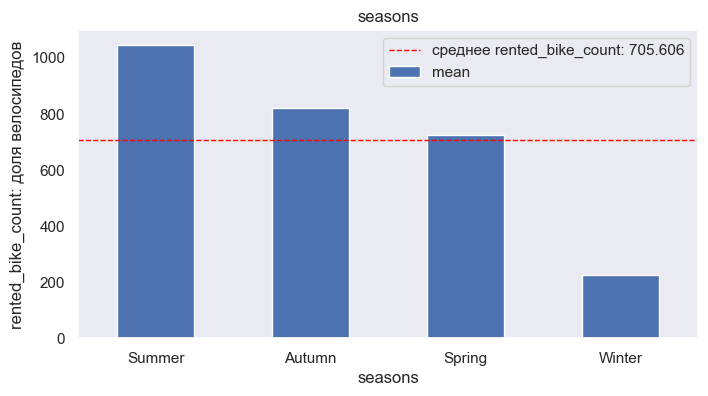

In [54]:
explorer_cat(
    df,
    'rented_bike_count',
    ['seasons'],
    'rented_bike_count: доля велосипедов')

In [55]:
def two_priznaka (tmp0, col_group, col_val_sum, title):
    '''
    
    группирует по приз col_group, средние значения по col_val_sum,
    строит график 
    title- подпись диагр
    tmp0 - датафрейм

    пример вывода:
    two_priznaka (df, 'seasons', 'rented_bike_count', 'Аренда велосипедов в среднем за сезон, шт.')
    '''
    
    df_season=tmp0.groupby(col_group)[col_val_sum].mean().reset_index().sort_values(by=col_val_sum, ascending=False)
    df_season.plot(x=col_group, y=col_val_sum, kind='bar')
    plt.title(title)
    plt.xlabel(f'{col_group}')
    plt.ylabel(f'{col_val_sum}, шт')
    plt.show()



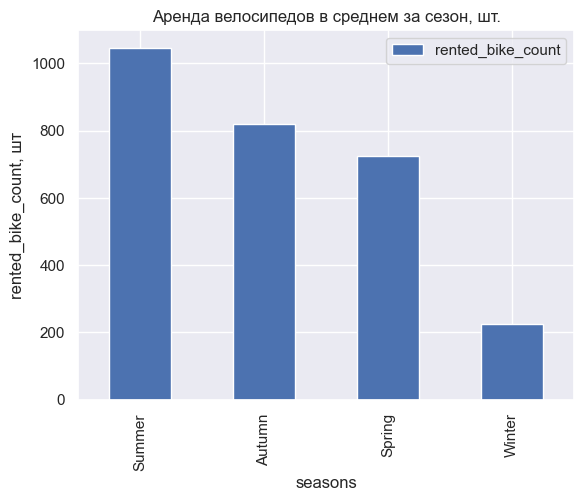

In [56]:
two_priznaka (df, 'seasons', 'rented_bike_count', 'Аренда велосипедов в среднем за сезон, шт.')

Изучаем спрос в праздничные дни



rented_bike_count: доля велосипедов holiday:
               mean  count
holiday                   
0        716.401920   6668
1        493.879412    340


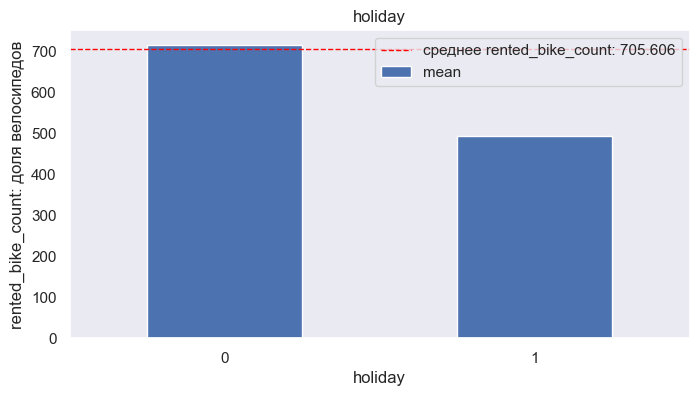

In [57]:
explorer_cat(
    df,
    'rented_bike_count',
    ['holiday'],
    'rented_bike_count: доля велосипедов')

In [58]:
def for_binar_priznak (tmp0, col_group, binar_val, title):
    '''
    
    группирует по приз col_group, бинарный признак binar_val,
    признак col_group - категориальный
    строит график 
    title- подпись диагр
    tmp0 - датафрейм

    пример вывода:
    for_binar_priznak (df, 'seasons', 'holiday', 'Аренда велосипедов по выходным, шт.')
    '''
    
    df_season=tmp0.groupby(col_group)[binar_val].value_counts(normalize=True).unstack(fill_value=0)
    df_season.plot(kind='bar')
    plt.title(title)
    plt.xlabel(f'{col_group}')
    plt.ylabel(f'{binar_val}, шт')
    plt.show()



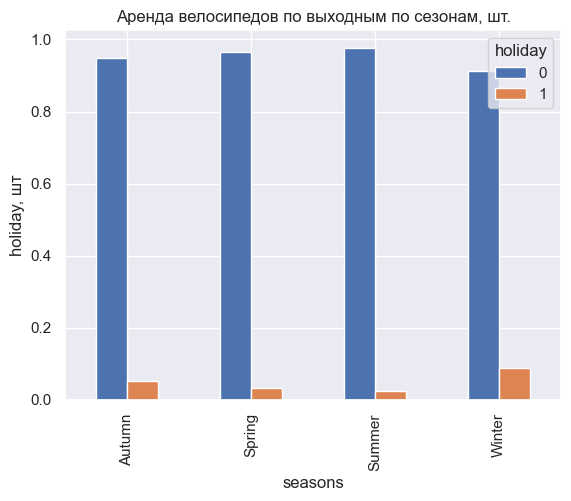

In [59]:
for_binar_priznak (df, 'seasons', 'holiday', 'Аренда велосипедов по выходным по сезонам, шт.')

Спрос на велосипеды в рабочее время по сезонам

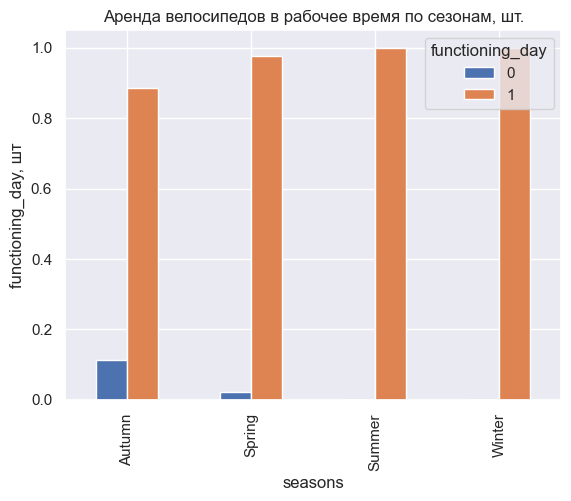

In [60]:
for_binar_priznak (df, 'seasons', 'functioning_day', 'Аренда велосипедов в рабочее время по сезонам, шт.')

Таким образом, в основном велосипеды арендуют **в рабочее время**, во все сезоны. Летом и Зимой загрузка 100%

По праздникам и выходным арендуют мало, около 1% зимой (максимальный спрос) и осеннью 0,5%. Летом арендуют меньше всего.


rented_bike_count: доля велосипедов functioning_day:
                       mean  count
functioning_day                   
1                730.843482   6766
0                  0.000000    242


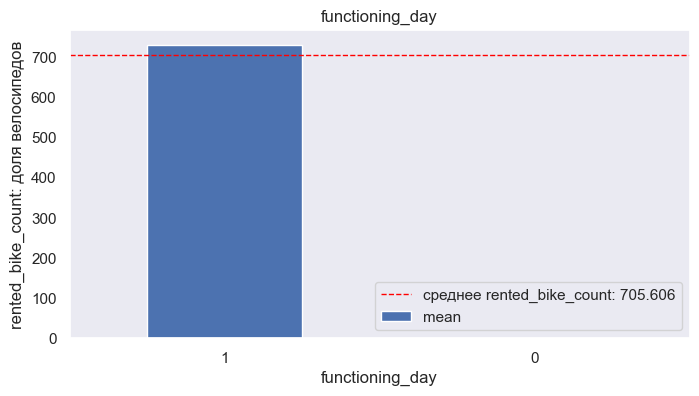

In [61]:
explorer_cat(
    df,
    'rented_bike_count',
    ['functioning_day'],
    'rented_bike_count: доля велосипедов')


rented_bike_count: доля велосипедов time_period_night:
                         mean  count
time_period_night                   
False              844.703140   5255
True               288.632059   1753


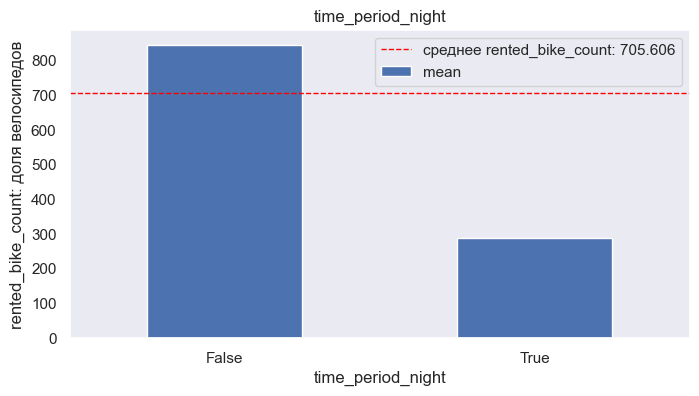

In [62]:
explorer_cat(
    df,
    'rented_bike_count',
    ['time_period_night'],
    'rented_bike_count: доля велосипедов')


rented_bike_count: доля велосипедов time_period_evening:
                            mean  count
time_period_evening                    
True                 1193.979452   1168
False                 607.931336   5840


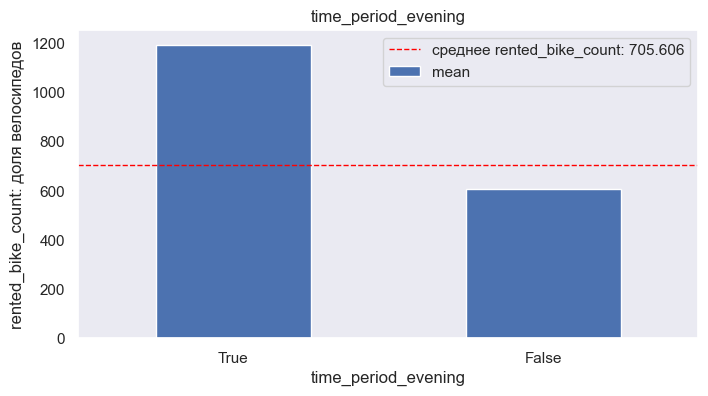

In [63]:
explorer_cat(
    df,
    'rented_bike_count',
    ['time_period_evening'],
    'rented_bike_count: доля велосипедов')


rented_bike_count: доля велосипедов time_period_late_evening:
                                mean  count
time_period_late_evening                   
True                      927.049446   1173
False                     661.089632   5835


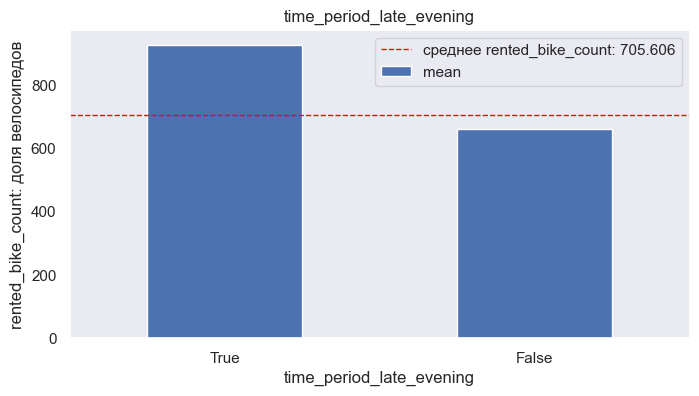

In [64]:
explorer_cat(
    df,
    'rented_bike_count',
    ['time_period_late_evening'],
    'rented_bike_count: доля велосипедов')


rented_bike_count: доля велосипедов time_period_morning:
                           mean  count
time_period_morning                   
False                717.910041   5836
True                 644.337884   1172


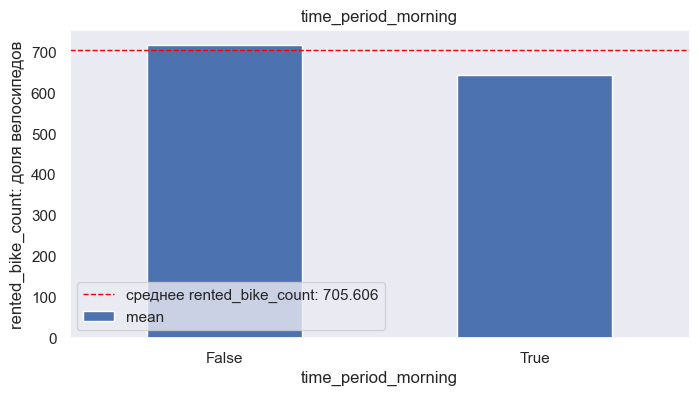

In [65]:
explorer_cat(
    df,
    'rented_bike_count',
    ['time_period_morning'],
    'rented_bike_count: доля велосипедов')

Наблюдаются графики зависимости 'rented_bike_count' от признаков:

- 'seasons' - зависимость есть. Сильнее всего спрос летом и осенью
- в выходные ('holiday') спрос ниже среднего, не большой, но в рабочее время ('functioning_day') - выше среднего
  
В основном велосипеды арендуют **в рабочее время**, во все сезоны. Летом и Зимой загрузка 100%.

По праздникам и выходным арендуют мало, около 1% зимой (максимальный спрос) и осеннью 0,5%. Летом арендуют меньше всего.

- в зависимости от времени суток, самый популярный спрос - вечер ('time_period_evening') и поздний вечер 

Таким образом, наблюдаются зависимость 'rented_bike_count': от сезона (лето, осень), от спроса в рабочее время, и вечернее время суток.

#### Построим корреляции и выявим наиболее сильные из них с признаком rented_bike_count 

In [66]:
df.columns

Index(['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count'],
      dtype='object')

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7008 entries, 3056 to 2749
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               7008 non-null   float32
 1   humidity                  6758 non-null   float32
 2   wind_speed_ms             6798 non-null   float32
 3   visibility_10m            6749 non-null   float32
 4   dew_point_temperature     7008 non-null   float32
 5   solar_radiation_mjm2      6798 non-null   float32
 6   rainfallmm                6746 non-null   float32
 7   snowfall_cm               6745 non-null   float32
 8   seasons                   7008 non-null   object 
 9   holiday                   7008 non-null   int8   
 10  functioning_day           7008 non-null   int8   
 11  time_period_evening       7008 non-null   bool   
 12  time_period_late_evening  7008 non-null   bool   
 13  time_period_morning       7008 non-null   bool   
 14  time_perio

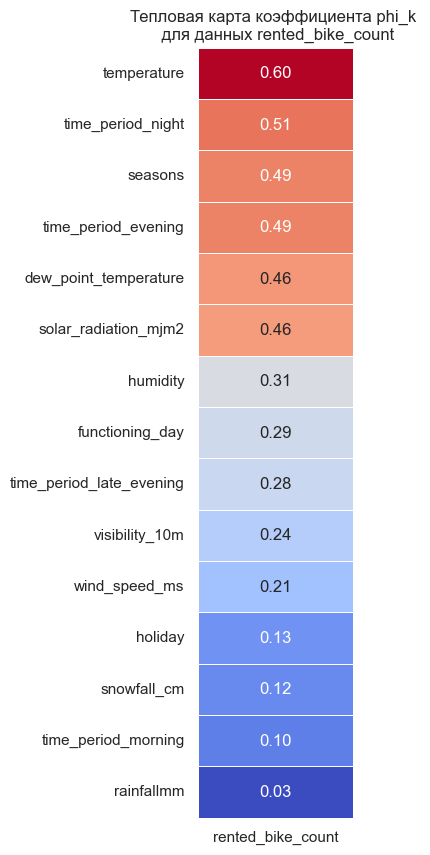

In [68]:
def correl_matrix_column(value, col):
    '''
    Строит тепловую карту по корреляционной матрицы для заданной переменной 
    value - столбцы/столбец
    col- столбец, для которого выводят коэффициенты корреляции
    interval_cols - список непрерывных признаков
    При использовании phik крайне важно настроить параметр interval_cols, передав ему список с 
    названиями непрерывных признаков: если этого не сделать, библиотека своими силами будет 
    пытаться разнести признаки по типам, и она часто делает в этом ошибки - от этого в свою очередь 
    мы получаем некорректную оценку корреляций, так как от типа признака зависит метод оценки корреляции.
    '''
    continuous_features = ['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count' 
        ]
    
    correlation_matrix = df[value].phik_matrix(interval_cols=continuous_features)
    
    
    plt.figure(figsize=(2, 10))
    correlation_matrix.loc[correlation_matrix.index != col][[col]].sort_values(by=col, ascending=False)
     
    data_heatmap = correlation_matrix.loc[correlation_matrix.index != col][[col]].sort_values(by=col, ascending=False)
    sns.heatmap(data_heatmap,
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm', 
            linewidths=0.5, 
            cbar=False 
           )
    plt.title(f'Тепловая карта коэффициента phi_k \n для данных {col}')
    plt.show()
    


correl_matrix_column(['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count'], 'rented_bike_count')

Самая сильная корреляция с признаком - temperature

средние, от 0,51 до 0,45 с признаками - time_period_night, seasons, time_period_evening, dew_point_temperature, 'wather_autumn', 'wather_spring', 'wather_summer', 'wather_winter', 'solar_radiation_mjm2'

Построим **тепловую карту взаимосвязей между всеми признаками**

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7008 entries, 3056 to 2749
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               7008 non-null   float32
 1   humidity                  6758 non-null   float32
 2   wind_speed_ms             6798 non-null   float32
 3   visibility_10m            6749 non-null   float32
 4   dew_point_temperature     7008 non-null   float32
 5   solar_radiation_mjm2      6798 non-null   float32
 6   rainfallmm                6746 non-null   float32
 7   snowfall_cm               6745 non-null   float32
 8   seasons                   7008 non-null   object 
 9   holiday                   7008 non-null   int8   
 10  functioning_day           7008 non-null   int8   
 11  time_period_evening       7008 non-null   bool   
 12  time_period_late_evening  7008 non-null   bool   
 13  time_period_morning       7008 non-null   bool   
 14  time_perio

<function matplotlib.pyplot.show(close=None, block=None)>

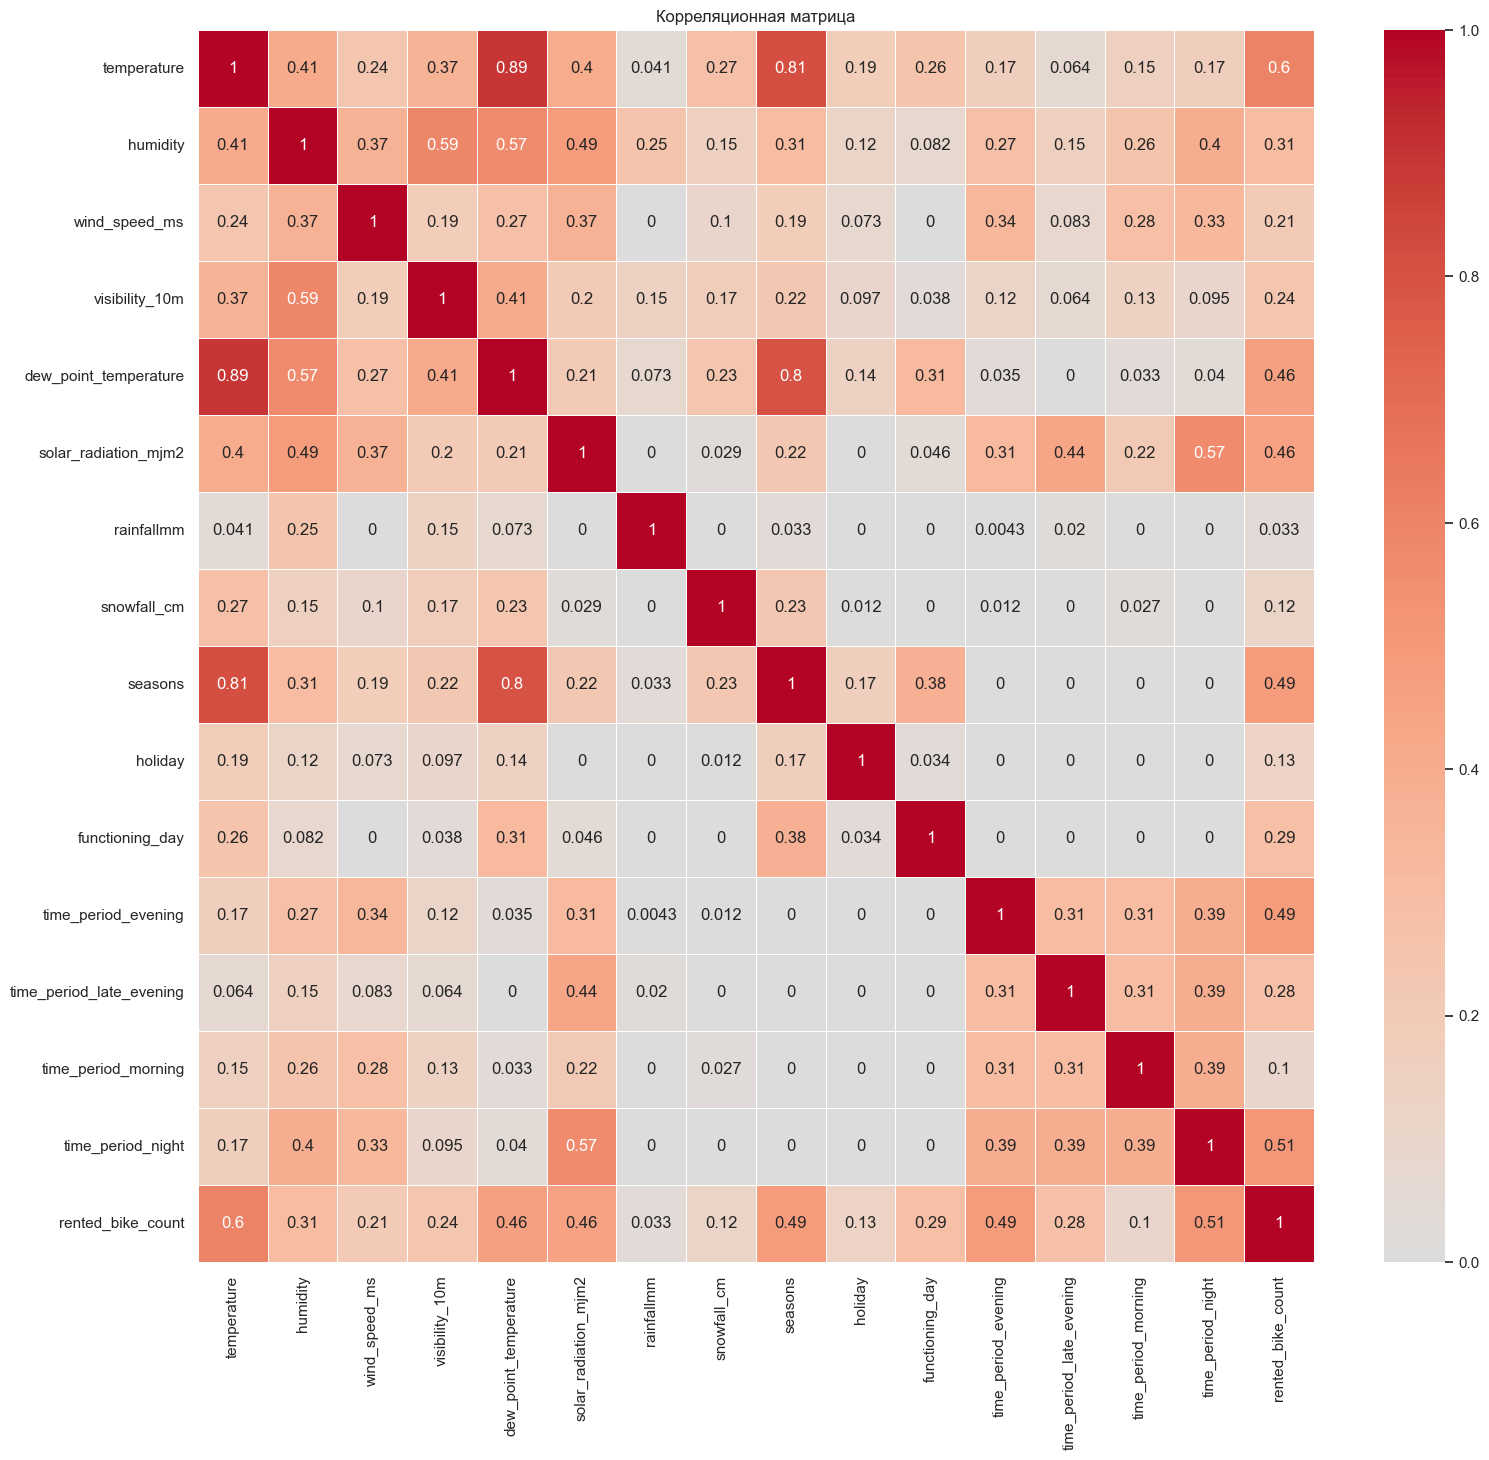

In [70]:
columns_for_analiz=['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count']

continuous_features =['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count']
correlation_matrix=df[columns_for_analiz].phik_matrix(interval_cols=continuous_features)
plt.figure(figsize=(18, 16))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Корреляционная матрица')
plt.show

самая сильная корреляция 0,89: dew_point_temperature и temperature
затем, по 0,8: temperature и seasons; seasons и dew_point_temperature

хочется удалить dew_point_temperature, но пока оставим, поскольку методы kNN не чувствителен к колинеарности

**Выводы по EDA:**

1. **Изучение категориальных признаков показало:**

- `seasons` - 4 категории, более активно арендуют осенью. Но равномерное распределение по всем сезонам.
- `holiday` - мало арендуют в выходные, сильный дисбаланс
- `functioning_day` - 90% арендуют в рабочее время
- `'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night'` - по временным интервалам чаще арендуют ночью

Распределение в долях категориальной seasons по бинарным признакам показало, что:
-	в выходные чаще арендуют зимой (лидер), и осенью. Наблюдается зависимость от времен года
-	в рабочее время аренда велосипедов чаще зимой и летом. Слабая зависимость.
-	по пременным интервалам и сезонам зависимости нет

*Есть выбросы, но модели kNN и дерево решений не чувствительны к ним, поэтому предобратоткой их заниматься не будем*



2. ГРАФИКИ **распределение целевой переменной Rented Bike Count**
- Основная часть значений (75%) находится в пределах до 1070 велосипедов в день. Среднее значение не совпадает с медианой, есть выбросы, график "волнистый", значит возможны сезонные колебания
-  На диаграммах рассеяния просматриаются хорошие зависимости rented_bike_count от temperature и solar_radiation_mjm2, более слабые обратные от snowfall_cm и  rainfallmm.
- Сравнивая спрос в разное время суток и сезоны обнаружили зависимость 'rented_bike_count': от сезона (лето, осень), а также от спроса в рабочее время, и вечернее время суток.


3. КОРРЕЛЯЦИИ **rented_bike_count**: наблюдается зависимоть от температуры, сезонов, вечерними и ночными арендами в сутках

- Самая сильная корреляция с признаком - temperature (0.6)
- Средние корреляции от 0.51 до 0.45 с признаками - `time_period_night, seasons, time_period_evening, dew_point_temperature, 'solar_radiation_mjm2'`

Исследование взамосиязей между всеми признаками выявило сильные корреляции между: 
- dew_point_temperature и temperature (0.89); 
- temperature и seasons (0.8);
- seasons и dew_point_temperature (0.8)
*******************************************************
**РЕЗУЛЬТАТЫ EDA:**
- Выводы, сделанные по графикам подтверждаются корреляциями. 
- Спрос зависит от температуры (`temperature`), солнечной радиации (`solar_radiation_mjm2`) и осадков (`time_period_night, seasons, time_period_evening, dew_point_temperature`).
- Целевая переменная `rented_bike_count` распределена нелинейно. Обнаружены колебания от времени года (`seasons`) и времени суток (`time_period_evening, time_period_late_evening, time_period_night`). 
- В основном пользуются велосипедами в рабочее время (`functioning_day`), не в праздники.

## 3.	Подготовка данных и baseline-модели

### Разделяю df на обучающую и валидационную выборки

Разбиваю на: X и y

In [71]:
X=df.drop('rented_bike_count', axis=1)
y=df['rented_bike_count']

Выделяю train и val выборки

In [72]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SEED)

In [73]:
print('Размеры выборок')
print("*"*40)
display('Выборка | Размер | Цель')
print("*"*40)
display(f'X_train, {len(X_train)}, проверка/обучение базовых моделей')
display(f'y_train, {len(y_train)}, проверка/обучение базовых моделей')
display(f'X_val  , {len(X_val)}, отбор гиперпараметров моделей')
display(f'y_val  , {len(X_val)}, отбор гиперпараметров моделей')

Размеры выборок
****************************************


'Выборка | Размер | Цель'

****************************************


'X_train, 5606, проверка/обучение базовых моделей'

'y_train, 5606, проверка/обучение базовых моделей'

'X_val  , 1402, отбор гиперпараметров моделей'

'y_val  , 1402, отбор гиперпараметров моделей'

### Подготовим пайплайн для предобработки данных

In [74]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7008 entries, 3056 to 2749
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               7008 non-null   float32
 1   humidity                  6758 non-null   float32
 2   wind_speed_ms             6798 non-null   float32
 3   visibility_10m            6749 non-null   float32
 4   dew_point_temperature     7008 non-null   float32
 5   solar_radiation_mjm2      6798 non-null   float32
 6   rainfallmm                6746 non-null   float32
 7   snowfall_cm               6745 non-null   float32
 8   seasons                   7008 non-null   object 
 9   holiday                   7008 non-null   int8   
 10  functioning_day           7008 non-null   int8   
 11  time_period_evening       7008 non-null   bool   
 12  time_period_late_evening  7008 non-null   bool   
 13  time_period_morning       7008 non-null   bool   
 14  time_perio

In [75]:
num_columns=X.select_dtypes(include=['number']).columns.tolist()
object_columns=X.select_dtypes(include=['object']).columns.tolist()
binary_columns=X.select_dtypes(include=['bool']).columns.tolist()

Поскольку будем использовать модели **kNN и дерево решений** то:
- по пропуски заполним значением-флагом, чтобы по ним тоже пранализировать информацию
- выбросы не будем обрабатывать, поскольку они не мешают алгоритмам kNN и дерево решений
- **для kNN масштабируем признаки, для корректной работы метрик**
- для преобразования категориальных признаков используем OneHotEncoder
- Для преобразования булевых признаков OneHotEncoder используем drop='first' (удалим одну колонку) 
- remainder='passthrough' - остальные признаки останутся без изменений

Поскольку для kNN требуются масштабированные признаки, а для дерева решений - нет. То создадим два препроцессора для каждой модели

### **kNN**. Создание препроцессора, пайплайна и его обучение

In [76]:
preprocessor=ColumnTransformer(
    transformers=[
        ('num_columns', Pipeline(steps=[
            ('inputer',SimpleImputer(fill_value=-999999)),
            ('scaler', StandardScaler()) ]), num_columns),
        ('object_columns', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), object_columns),
        ('binary_columns', OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first'),binary_columns)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

In [77]:
kNN_pipe=Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('kNN', KNeighborsRegressor())
])

Обучаю модель kNN

In [78]:
kNN_pipe.fit(X_train, y_train)
print('Обучение завершено')

Обучение завершено


Посчитаем метрики

In [79]:
metrics={
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

scores_kNN = cross_validate(
    kNN_pipe,
    X_train,
    y_train,
    cv=cv, 
    scoring=metrics,
    return_train_score=True, 
    n_jobs=-1 
)

In [80]:
for metric, scores in scores_kNN.items():
    if "test" in metric:
        print(f"Среднее значение {metric.replace('test_', '')}: {scores.mean():.3f}")

for metric, scores in scores_kNN.items():
    if "test" in metric:
        print(f"Стандартное отклонение {metric.replace('test_', '')}: {scores.std():.4f}")

Среднее значение RMSE: -324.469
Среднее значение MAE: -215.529
Среднее значение R2: 0.745
Стандартное отклонение RMSE: 3.6591
Стандартное отклонение MAE: 3.8535
Стандартное отклонение R2: 0.0102


Метрики получились ниже, чем в модели заказчика:

Среднее значение RMSE: -329.898
Среднее значение MAE: -219.079
Среднее значение R2: 0.740
Стандартное отклонение RMSE: 8.9683
Стандартное отклонение MAE: 5.0204
Стандартное отклонение R2: 0.0144

#### Подбор гиперпараметров с Optuna для kNN

In [81]:
def objective(trial):
    params = {
        'n_neighbors': trial.suggest_int('n_neighbors', 3, 20),
        'weights': trial.suggest_categorical('weights', ['uniform', 'distance']),
        'metric': trial.suggest_categorical('metric', ['manhattan', 'euclidean'])
    }
    model_kNN = KNeighborsRegressor(**params)   

    pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', model_kNN)
            ])                              

    scores = cross_val_score(
            pipeline,
            X_train,
            y_train,
            cv=3,
            scoring=make_scorer(root_mean_squared_error)  
        )
    mean_score = scores.mean()      

    
    trial.report(mean_score, step=0)


    return scores.mean() 

Создаём исследование

In [82]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_SEED)

study_knn = optuna.create_study(direction="minimize", sampler=sampler) 

[I 2026-10-29 16:47:46,943] A new study created in memory with name: no-name-e92d761a-2eba-4582-8b5f-9ab2b2cb2b40


Запускаем оптимизацию

In [83]:
study_knn.optimize(objective, n_trials=20, show_progress_bar=True)

  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-10-29 16:47:47,223] Trial 0 finished with value: 315.54101216967865 and parameters: {'n_neighbors': 9, 'weights': 'uniform', 'metric': 'manhattan'}. Best is trial 0 with value: 315.54101216967865.
[I 2026-10-29 16:47:47,343] Trial 1 finished with value: 324.1773668186886 and parameters: {'n_neighbors': 5, 'weights': 'distance', 'metric': 'euclidean'}. Best is trial 0 with value: 315.54101216967865.
[I 2026-10-29 16:47:47,488] Trial 2 finished with value: 333.3450927435367 and parameters: {'n_neighbors': 3, 'weights': 'uniform', 'metric': 'manhattan'}. Best is trial 0 with value: 315.54101216967865.
[I 2026-10-29 16:47:47,638] Trial 3 finished with value: 315.0643398882706 and parameters: {'n_neighbors': 6, 'weights': 'distance', 'metric': 'manhattan'}. Best is trial 3 with value: 315.0643398882706.
[I 2026-10-29 16:47:47,767] Trial 4 finished with value: 314.74584543753303 and parameters: {'n_neighbors': 14, 'weights': 'distance', 'metric': 'euclidean'}. Best is trial 4 with va

In [84]:
print('Лучшие гиперпараметры:', study_knn.best_params)
print('Лучшая accuracy:', study_knn.best_value)

Лучшие гиперпараметры: {'n_neighbors': 12, 'weights': 'distance', 'metric': 'manhattan'}
Лучшая accuracy: 308.6554973867688


Лучшие гиперпараметры: {'n_neighbors': 9, 'weights': 'distance', 'metric': 'manhattan'}
Лучшая accuracy: 313.36775368571097

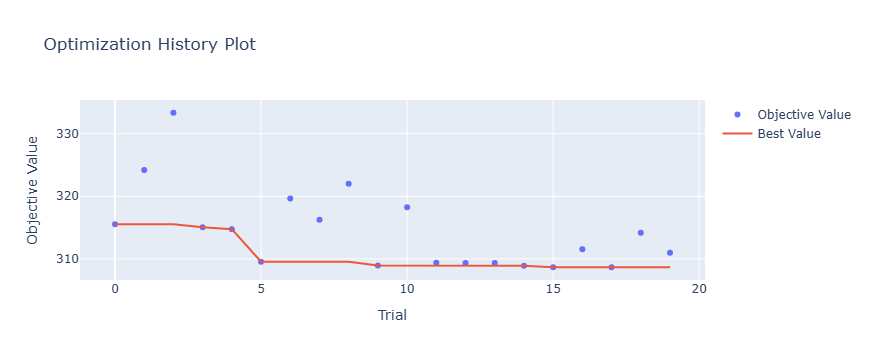

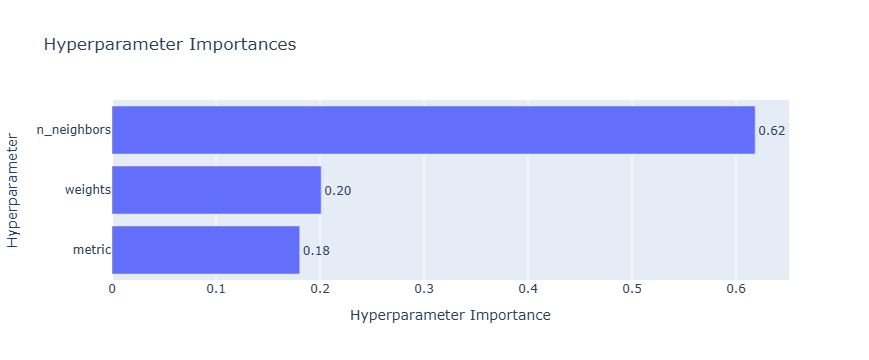

In [85]:
fig1 = optuna.visualization.plot_optimization_history(study_knn)  
fig2 = optuna.visualization.plot_param_importances(study_knn)      

display(fig1)
display(fig2) 

#### Обучим лучшую модель kNN

In [86]:
best_kNN_model= KNeighborsRegressor(**study_knn.best_params)

In [87]:
fin_kNN_pipe=Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', best_kNN_model)
])

fin_kNN_pipe.fit(X_train, y_train)
print('Обучение завершено')

Обучение завершено


#### Оцениваем важность признаков по модели kNN

fin_kNN_pipe=Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', best_kNN_model)
])

В модели kNN нет параметра feature_importances_ , поэтому для важности признаков используем метод `PermutationImportance` - оценивает важность признаков, перемешивая строки и снова высчитывая качество модели. Если качество упало - признак значим

all_importances - создадим массив для хранения важности признака

cv - параметры кросс-валидации оценки

In [88]:
all_importances = []

Разбиваем обучающую выборку на фолды. На каждой итерации прогоняем выборку через пайплайн, обучаем и оцениваем важность признаков (PermutationImportance). Важные признаки сохраняем в all_importances.

In [89]:
for train_idx, val_idx in cv.split(X_train):
    
    X_inner_train, X_inner_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_inner_train, y_inner_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    
    pipe_clone = Pipeline(steps=[
        ('preprocessor', fin_kNN_pipe.named_steps['preprocessor']),
        ('regressor', KNeighborsRegressor(**study_knn.best_params))
    ])
    pipe_clone.fit(X_inner_train, y_inner_train)
    
    perm = PermutationImportance(
        pipe_clone.named_steps['regressor'], 
        scoring=make_scorer(root_mean_squared_error), 
        n_iter=10, 
        random_state=RANDOM_SEED
    )
    
    X_val_transformed = pipe_clone.named_steps['preprocessor'].transform(X_inner_val)
    perm.fit(X_val_transformed, y_inner_val)
    
    all_importances.append(perm.feature_importances_)


Усредняем веса признаков

Сохраняем в датафрейм признаки и веса. Выводим топ10

In [90]:
mean_importances = np.mean(all_importances, axis=0)
feature_names = fin_kNN_pipe.named_steps['preprocessor'].get_feature_names_out()

importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': mean_importances
}).sort_values('importance')

display(importance_df.head(10))

,feature,importance
9,functioning_day,-90.613894
14,time_period_evening_True,-64.585303
1,humidity,-54.435561
5,solar_radiation_mjm2,-53.791073
0,temperature,-46.331036
17,time_period_night_True,-35.919128
15,time_period_late_evening_True,-33.558760
4,dew_point_temperature,-27.917863
3,visibility_10m,-17.094351
2,wind_speed_ms,-13.457275


**Отразим на диаграмме важные признаки kNN**

In [91]:
top10_features=importance_df['feature'].values[:10]
top10_importances=importance_df['importance'].values[:10]

abs_importances = np.abs(top10_importances)

In [92]:
%%capture fig_capture_kNN
plt.figure(figsize=(8, 5))
plt.barh(top10_features, abs_importances)
plt.xlabel('Важность признака')
plt.title('Важность признака в kNN')
plt.gca().invert_yaxis()
plt.show()

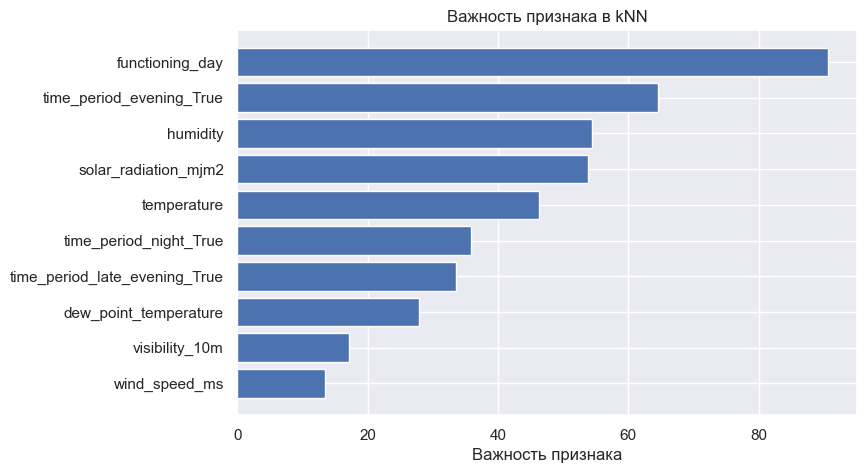

In [93]:
fig_capture_kNN.show()

В модели kNN на спрос аренды велосипеда влияют: 
- аренда вечером, солнечная активность, влажность и температура
- а также: аренда поздним вечером, аренда в рабочее время, аренда ночью , температура


### **Дерево решений**. Создание препроцессора, пайплайна и его обучение

In [94]:
tree_preprocessor=ColumnTransformer(
    transformers=[
        ('num_columns', SimpleImputer(fill_value=-999999), num_columns),
        ('object_columns', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), object_columns),
        ('binary_columns', OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first'),binary_columns)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

Инициируем модель для дерева решений

In [95]:
tree_model=DecisionTreeRegressor(max_depth=10, random_state=RANDOM_SEED)

In [96]:
tree_pipe=Pipeline(steps=[
    ('tree_preprocessor', tree_preprocessor),
    ('TDC', tree_model)
])

Обучаем пайплайн

In [97]:
tree_pipe.fit(X_train, y_train)
print('Обучение завершено')

Обучение завершено


In [98]:
metrics_tree={
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

scores_tree = cross_validate(
    tree_pipe,
    X_train,
    y_train,
    cv=cv, 
    scoring=metrics_tree,
    return_train_score=True, 
    n_jobs=-1 
)

In [99]:
for metric, scores in scores_tree.items():
    if "test" in metric:
        print(f"Среднее значение {metric.replace('test_', '')}: {scores.mean():.3f}")

for metric, scores in scores_tree.items():
    if "test" in metric:
        print(f"Стандартное отклонение {metric.replace('test_', '')}: {scores.std():.4f}")

Среднее значение RMSE: -331.198
Среднее значение MAE: -217.227
Среднее значение R2: 0.734
Стандартное отклонение RMSE: 13.4348
Стандартное отклонение MAE: 4.6035
Стандартное отклонение R2: 0.0197


Дерево решений, базовые метрики

Среднее значение RMSE: -330.665
Среднее значение MAE: -215.311
Среднее значение R2: 0.739
Стандартное отклонение RMSE: 8.9683
Стандартное отклонение MAE: 5.0204
Стандартное отклонение R2: 0.0144

#### Подбор гиперпараметров с Optuna

In [100]:
def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 3, 15),                           
        'criterion': trial.suggest_categorical('criterion', ['squared_error', 'absolute_error', 'friedman_mse', 'poisson'])      
    }

    model = DecisionTreeRegressor(random_state=RANDOM_SEED, **params)   

    pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', model)
            ])                              

    scores = cross_val_score(
            pipeline,
            X_val,
            y_val,
            cv=3,
            scoring=make_scorer(root_mean_squared_error)  
        )
    mean_score = scores.mean()      

    
    trial.report(mean_score, step=0)


    return scores.mean() 

Создаём исследование

In [101]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_SEED)

study = optuna.create_study(direction="minimize", sampler=sampler) 


[I 2026-10-29 16:48:07,960] A new study created in memory with name: no-name-31b3f244-59ab-43b5-b2cd-3c9f4f5d42e7


Запускаем оптимизацию

In [102]:
study.optimize(objective, n_trials=20, show_progress_bar=True)

  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-10-29 16:48:08,073] Trial 0 finished with value: 371.29657470607845 and parameters: {'max_depth': 7, 'criterion': 'squared_error'}. Best is trial 0 with value: 371.29657470607845.
[I 2026-10-29 16:48:08,232] Trial 1 finished with value: 423.4796998763051 and parameters: {'max_depth': 5, 'criterion': 'absolute_error'}. Best is trial 0 with value: 371.29657470607845.
[I 2026-10-29 16:48:08,304] Trial 2 finished with value: 487.00322054852995 and parameters: {'max_depth': 3, 'criterion': 'squared_error'}. Best is trial 0 with value: 371.29657470607845.
[I 2026-10-29 16:48:08,459] Trial 3 finished with value: 423.4796998763051 and parameters: {'max_depth': 5, 'criterion': 'absolute_error'}. Best is trial 0 with value: 371.29657470607845.
[I 2026-10-29 16:48:08,544] Trial 4 finished with value: 503.91596186578835 and parameters: {'max_depth': 10, 'criterion': 'poisson'}. Best is trial 0 with value: 371.29657470607845.
[I 2026-10-29 16:48:08,648] Trial 5 finished with value: 433.2938

Посмотрим результаты, выведем наилучшие параметры

In [103]:
print('Лучшие гиперпараметры:', study.best_params)
print('Лучшая accuracy:', study.best_value)

Лучшие гиперпараметры: {'max_depth': 7, 'criterion': 'squared_error'}
Лучшая accuracy: 371.29657470607845


Визуализирую результаты

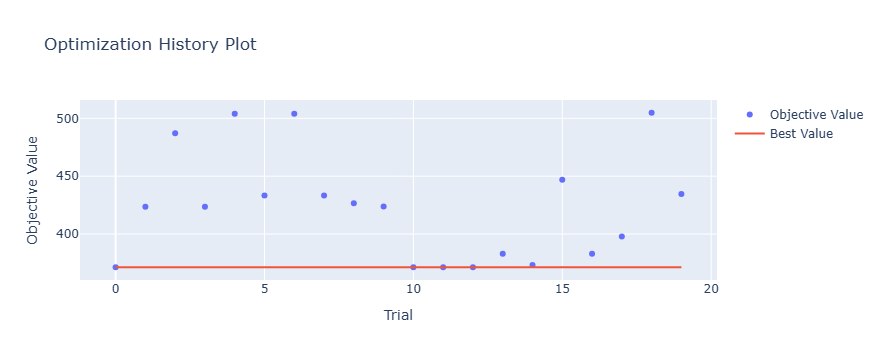

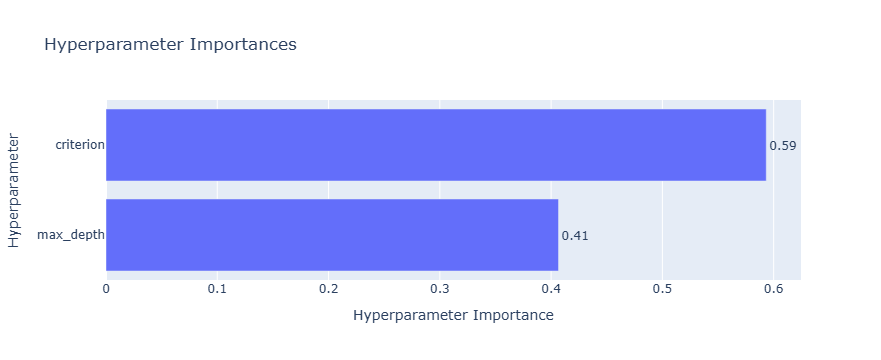

In [104]:
fig1 = optuna.visualization.plot_optimization_history(study)  
fig2 = optuna.visualization.plot_param_importances(study)      

display(fig1)
display(fig2) 


#### Обучим лучшую модель DTR

In [105]:
best_tree_model= DecisionTreeRegressor(random_state=RANDOM_SEED, **study.best_params)

In [106]:
fin_tree_pipe=Pipeline(steps=[
    ('tree_preprocessor', tree_preprocessor),
    ('TDC', best_tree_model)
])

fin_tree_pipe.fit(X_train, y_train)
print('Обучение завершено')

Обучение завершено


#### Оцениваем важность признаков по модели Дерево решений

Рассчитываем feature_importance. Сохраним в переменные отдельные этапы пайплайна с лучшей моделью `fin_tree_pipe` 

In [107]:
preprocessor=fin_tree_pipe.named_steps['tree_preprocessor']
model=fin_tree_pipe.named_steps['TDC']

Создаём таблицу с feature_importance 

In [108]:
feature_importance=pd.DataFrame(
   { 'feature': preprocessor.get_feature_names_out(),
    'importance': model.feature_importances_}
).sort_values('importance', ascending=False)

Визуализируем 10 наиважнейших признаков модели

In [109]:
top10_features=feature_importance['feature'].values[:10]
top10_importances=feature_importance['importance'].values[:10]

Отразим на столбиковой диаграмме 10 важнейших признаков

Чтобы использовать диаграмму ниже в отчёте, сохраним её вывод в переменную `fig_capture_tree` с помощью команды:

`%%capture fig_capture_tree`

Теперь в отчёте для вывода пропишем: 

`fig_capture_tree.show()`

In [110]:
%%capture fig_capture_tree
plt.figure(figsize=(8, 5))
plt.barh(top10_features, top10_importances)
plt.xlabel('Важность признака')
plt.title('Важность признака в дереве решений')
plt.gca().invert_yaxis()
plt.show()

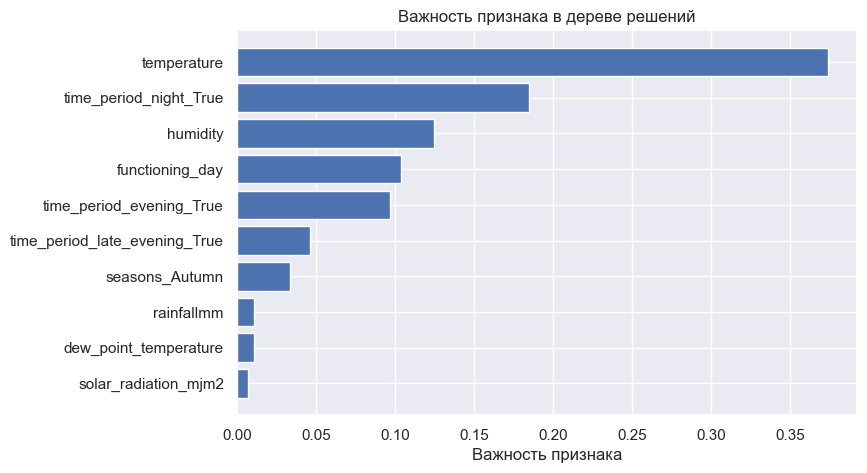

In [111]:
fig_capture_tree.show()

Модель дерева решений показывает, что:
1. спрос на велосипеды очень сильно зависит от **температуры** и пикового времени: **вечер**
2. более слабое влияние на спрос оказывают: время аренды: поздний вечер, солнечная активность, влажность и поездка в рабочее время.

## Кросс-валидация новых моделей

### Кросс-валидация лучшей модели kNN

In [112]:
metrics={
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

scores_best_kNN = cross_validate(
    fin_kNN_pipe,
    X_train,
    y_train,
    cv=cv, 
    scoring=metrics,
    return_train_score=True, 
    n_jobs=-1 
)

In [113]:
for metric, scores in scores_best_kNN.items():
    if "test" in metric:
        print(f"Среднее значение {metric.replace('test_', '')}: {scores.mean():.3f}")

for metric, scores in scores_best_kNN.items():
    if "test" in metric:
        print(f"Стандартное отклонение {metric.replace('test_', '')}: {scores.std():.4f}")

Среднее значение RMSE: -304.807
Среднее значение MAE: -203.881
Среднее значение R2: 0.775
Стандартное отклонение RMSE: 6.0876
Стандартное отклонение MAE: 3.9679
Стандартное отклонение R2: 0.0116


### Кросс-валидация лучшей модели DTC, дерево решений

In [114]:
metrics={
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

scores_fin_tree = cross_validate(
    fin_tree_pipe,
    X_train,
    y_train,
    cv=cv, 
    scoring=metrics,
    return_train_score=True, 
    n_jobs=-1 
)

In [115]:
for metric, scores in scores_fin_tree.items():
    if "test" in metric:
        print(f"Среднее значение {metric.replace('test_', '')}: {scores.mean():.3f}")
for metric, scores in scores_fin_tree.items():
    if "test" in metric:
        print(f"Стандартное отклонение {metric.replace('test_', '')}: {scores.std():.4f}")

Среднее значение RMSE: -336.921
Среднее значение MAE: -226.704
Среднее значение R2: 0.724
Стандартное отклонение RMSE: 10.8146
Стандартное отклонение MAE: 3.3641
Стандартное отклонение R2: 0.0201


## Сравнение метрик с baseline-моделью.
Определите, какая модель показывает лучшие результаты на тренировочной выборке.

Сравниваем метрики **лучшей kNN** модели с **базовой** на train

In [116]:
dict_scores_basa_kNN={}
for metric, scores in scores_kNN.items():
    if "test" in metric:
        dict_scores_basa_kNN[metric.replace('test_', '')]=scores.mean().round(3)

dict_best_kNN={}
for metric, scores in scores_best_kNN.items():
    if "test" in metric:
        dict_best_kNN[metric.replace('test_', '')]=scores.mean().round(3)
display(f'Средние значения базовой kNN {dict_scores_basa_kNN}')
display(f'Средние значения лучшей kNN {dict_best_kNN}')

delta={}
for metric in dict_scores_basa_kNN:
    delta[metric]=round(dict_best_kNN[metric]-dict_scores_basa_kNN[metric], 3)
display('')
display('*'*100)
display('Разница kNN (Лучшая-Базовая)')
display('*'*100)
for metric, value in delta.items():
    if value >0:
        display(f'{metric}: {value} улучшение')
    elif value <0:
        display(f'{metric}: {value} ухудшение')
    else:
        display('без изменений')

"Средние значения базовой kNN {'RMSE': np.float64(-324.469), 'MAE': np.float64(-215.529), 'R2': np.float64(0.745)}"

"Средние значения лучшей kNN {'RMSE': np.float64(-304.807), 'MAE': np.float64(-203.881), 'R2': np.float64(0.775)}"

''

'****************************************************************************************************'

'Разница kNN (Лучшая-Базовая)'

'****************************************************************************************************'

'RMSE: 19.662 улучшение'

'MAE: 11.648 улучшение'

'R2: 0.03 улучшение'

Сравниваем метрики **лучшей модели: Дерево решений**  с **базовой** на train

In [117]:
dict_scores_basa_tree={}
for metric, scores in scores_tree.items():
    if "test" in metric:
        dict_scores_basa_tree[metric.replace('test_', '')]=scores.mean().round(3)

dict_scores_best_tree={}
for metric, scores in scores_fin_tree.items():
    if "test" in metric:
        dict_scores_best_tree[metric.replace('test_', '')]=scores.mean().round(3)
display(f'Средние значения базовой kNN {dict_scores_basa_tree}')
display(f'Средние значения лучшей kNN {dict_scores_best_tree}')

delta={}
for metric in dict_scores_basa_tree:
    delta[metric]=round(dict_scores_best_tree[metric]-dict_scores_basa_tree[metric], 3)
display('')
display('*'*100)
display('Разница: Дерево решений (Лучшая-Базовая)')
display('*'*100)
for metric, value in delta.items():
    if value >0:
        display(f'{metric}: {value} улучшение')
    elif value <0:
        display(f'{metric}: {value} ухудшение')
    else:
        display('без изменений')

"Средние значения базовой kNN {'RMSE': np.float64(-331.198), 'MAE': np.float64(-217.227), 'R2': np.float64(0.734)}"

"Средние значения лучшей kNN {'RMSE': np.float64(-336.921), 'MAE': np.float64(-226.704), 'R2': np.float64(0.724)}"

''

'****************************************************************************************************'

'Разница: Дерево решений (Лучшая-Базовая)'

'****************************************************************************************************'

'RMSE: -5.723 ухудшение'

'MAE: -9.477 ухудшение'

'R2: -0.01 ухудшение'

После подбора гиперпараметров в моделях kNN (ближайшего соседа) и DTC (дерево решений) заметны улучшения:
- RMSE снизилась (значит более точные предсказания)
- R2 повысился (значит лучше объясняет вариацию целевой переменной)

Следовательно, настройка гиперпараметров улучшила производительность моделей, особенно сильно - для kNN.

Лучшие результаты на тренировочной выборке показывает модель **kNN**

Ошибаются модели достаточно сильно, высокие значения по RMSE/MAE

## Составление отчёта по моделям

Что нужно сделать:

Составьте таблицу с метриками: baseline, KNN, Decision Tree.
Добавьте визуализацию, если необходимо: bar plot или box plot по RMSE/MAE.
Подготовьте выводы:

Какая модель лучше справляется с прогнозом?
Какие признаки, по вашему мнению, особенно важны?
Совет:

Старайтесь объяснить результаты в бизнес-контексте: «Эта модель лучше реагирует на дождь», «Температура и влажность сильно влияют на спрос в пиковые часы».

Функция для сравнения моделей, в отчёте буду использовать

In [118]:
def comparison_metrics(dict1, dict2, for_title):
    '''
    функция строит диаграмму сравнения метрик RMSE, MAE
    метрики выбираются из словарей
    dict1 - словарь метрик базовой модели
    dict2 - словарь метрик лучшей модели
    for_title - в заголовке указывается модель

    Пример вывода:
    comparison_metrics(dict_scores_basa_tree, dict_scores_best_tree, 'Дерево решений')
    '''
    select_keys = ['RMSE', 'MAE']

    df = pd.DataFrame({
        'Базовая модель': dict1,
        'Улучшенная модель': dict2    
    })

    df = df.loc[select_keys]

    ax = df.plot(kind='bar', figsize=(9, 5), rot=0, color=['green', 'blue'])

    for bar in ax.patches:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2, 
            height + 0.05, 
            f'{height:.2f}', 
            ha='center', 
            va='bottom',
            fontsize=10,
            fontweight='bold'
        )

    ax.set_ylabel('Значение метрики')
    ax.set_title(f'Сравнение метрик basa и best: {for_title}')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend(title='Модель')
    plt.tight_layout()
    plt.show()

**Итоговый отчёт**

'===================================================================================================='

'ТАБЛИЦА С МЕТРИКАМИ МОДЕЛЕЙ: модель BikeSochi, baseline, kNN, DTC НА train'

'===================================================================================================='

"модель BikeSochi: {'RMSE': np.float64(-413.901), 'MAE': np.float64(-310.092), 'R2': np.float64(0.589)}"

'===================================================================================================='

"baseline kNN: {'RMSE': np.float64(-324.469), 'MAE': np.float64(-215.529), 'R2': np.float64(0.745)}"

"  лучшая kNN: {'RMSE': np.float64(-304.807), 'MAE': np.float64(-203.881), 'R2': np.float64(0.775)}"

'===================================================================================================='

"baseline DTC: {'RMSE': np.float64(-331.198), 'MAE': np.float64(-217.227), 'R2': np.float64(0.734)}"

"  лучшая DTC: {'RMSE': np.float64(-336.921), 'MAE': np.float64(-226.704), 'R2': np.float64(0.724)}"

'График сравнения RMSE, MAE для kNN'

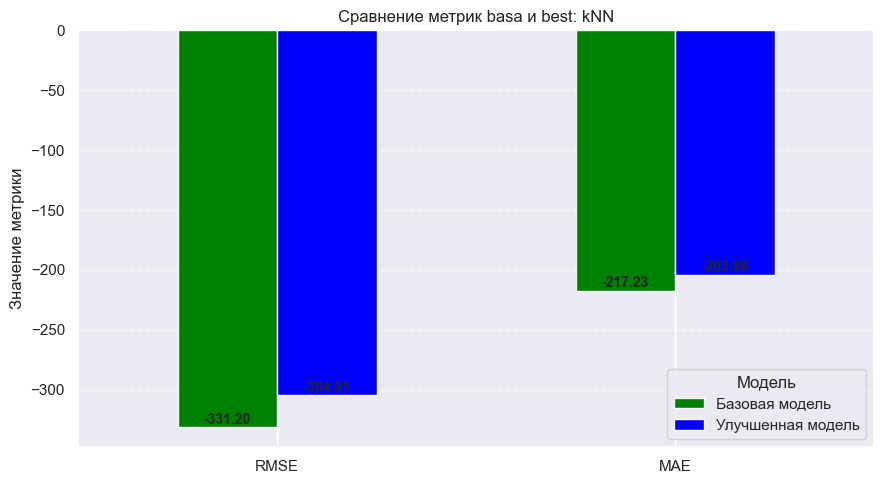

'График сравнения RMSE, MAE для Дерево решений'

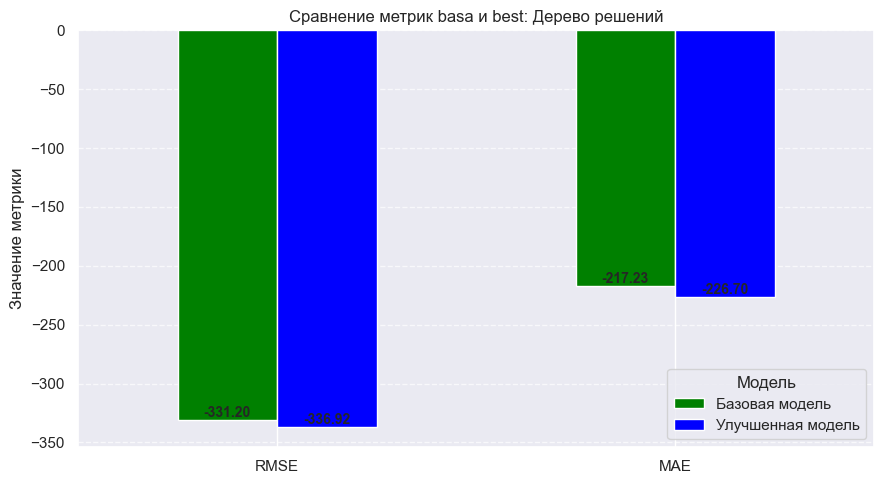

'===================================================================================================='

'После подбора гиперпараметров в моделях kNN (ближайшего соседа) и DTC (дерево решений) заметны улучшения:'

'- RMSE снизилась (значит более точные предсказания)'

'- R2 повысился (значит лучше объясняет вариацию целевой переменной)'

'Следовательно, настройка гиперпараметров улучшила производительность моделей, особенно сильно - для kNN.'

'Лучшие результаты на тренировочной выборке показывает модель kNN'

... (2 outputs left out)

'ЛУЧШАЯ МОДЕЛЬ - МОДЕЛЬ kNN (ближайших соседей), с более лучшими метриками'

'===================================================================================================='

'===================================================================================================='

'Важные признаки по kNN'

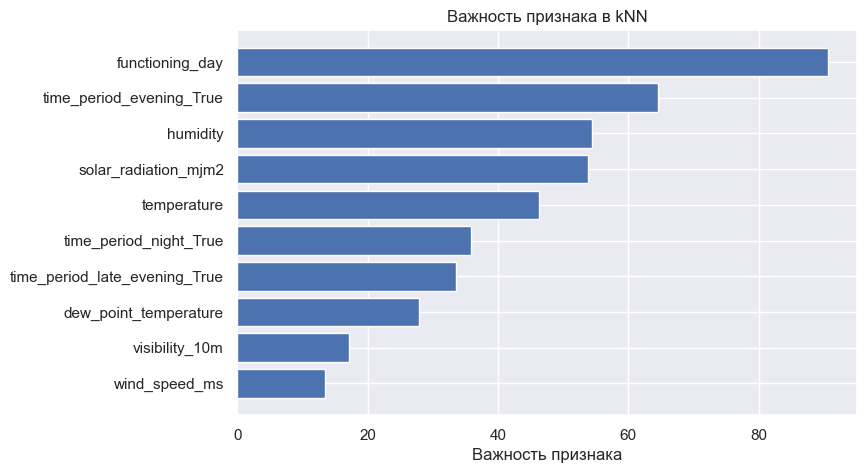

'В модели kNN на спрос аренды велосипеда влияют: '

'1. аренда вечером (16:00-19:50)'

'2. солнечная радиация, влажность и температура'

'3. а также: аренда поздним вечером (20:00-23:59), аренда в рабочее время, аренда ночью , точка росы'

In [119]:
display('='*100)
display('ТАБЛИЦА С МЕТРИКАМИ МОДЕЛЕЙ: модель BikeSochi, baseline, kNN, DTC НА train')
display('='*100)

display(f'модель BikeSochi: {metric_name_model0}')
display('='*100)

dict_scores_basa_kNN={}
for metric, scores in scores_kNN.items():
    if "test" in metric:
        dict_scores_basa_kNN[metric.replace('test_', '')]=scores.mean().round(3)

dict_best_kNN={}
for metric, scores in scores_best_kNN.items():
    if "test" in metric:
        dict_best_kNN[metric.replace('test_', '')]=scores.mean().round(3)
display(f'baseline kNN: {dict_scores_basa_kNN}')
display(f'  лучшая kNN: {dict_best_kNN}')


display('='*100)
dict_scores_basa_tree={}
for metric, scores in scores_tree.items():
    if "test" in metric:
        dict_scores_basa_tree[metric.replace('test_', '')]=scores.mean().round(3)

dict_scores_best_tree={}
for metric, scores in scores_fin_tree.items():
    if "test" in metric:
        dict_scores_best_tree[metric.replace('test_', '')]=scores.mean().round(3)
display(f'baseline DTC: {dict_scores_basa_tree}')
display(f'  лучшая DTC: {dict_scores_best_tree}')

display('График сравнения RMSE, MAE для kNN')
comparison_metrics(dict_scores_basa_tree, dict_best_kNN, 'kNN')

display('График сравнения RMSE, MAE для Дерево решений')
comparison_metrics(dict_scores_basa_tree, dict_scores_best_tree, 'Дерево решений')
display('='*100)
display(f'После подбора гиперпараметров в моделях kNN (ближайшего соседа) и DTC (дерево решений) заметны улучшения:',
f'- RMSE снизилась (значит более точные предсказания)',
f'- R2 повысился (значит лучше объясняет вариацию целевой переменной)',
f'Следовательно, настройка гиперпараметров улучшила производительность моделей, особенно сильно - для kNN.',
f'Лучшие результаты на тренировочной выборке показывает модель kNN',
f'Ошибаются модели достаточно сильно, высокие значения по RMSE/MAE')

display('='*100)
display('ЛУЧШАЯ МОДЕЛЬ - МОДЕЛЬ kNN (ближайших соседей), с более лучшими метриками')
display('='*100)


display('='*100)
display('Важные признаки по kNN')
fig_capture_kNN.show()
display(f'В модели kNN на спрос аренды велосипеда влияют: ',
f'1. аренда вечером (16:00-19:50)',
f'2. солнечная радиация, влажность и температура',
f'3. а также: аренда поздним вечером (20:00-23:59), аренда в рабочее время, аренда ночью , точка росы')


## Сохранение модели и отчёта

**Оценим лучшую модель kNN на тестовой выборке**

In [120]:
print('Лучшие гиперпараметры:', study_knn.best_params)

Лучшие гиперпараметры: {'n_neighbors': 12, 'weights': 'distance', 'metric': 'manhattan'}


Анализируя гиперпараметры модели kNN приходим к выводу, что у неё сложная структура:
- `n_neighbors`: **9** - модель делает предсказания, опираясь на значения 9 соседей (9 точек). Это значение не слишком маленькое, значит нет риска недообучиться и не учитывает лишний "шум". Но и не слишком большое, где модель не переобучится и не игнорирует локальные особенности.

  Чтобы получить устойчивое среднее значение модели надо 9 точек, не 3-4, это говорит о том. что в данных есть области с высокой плотностью похожих объектов (Возможно стоит повысить качество модели за сёт введения преобразований признаков, например, возведением в степень, чтобы "поймать" нелинейность);
- `'weights`: **distance** - означает, что вклад в целевую переменную у 9 точек не одинаковый. Ближние точки больше влияют, а вес дальних уменьшается с расстоянием. Такой параметр говорит о нелинейности процессов целевой переменной. (Справочно: uniform - равномерный вклад всех точек)
-  `metric`: **manhattan** - метрика, как считается расстояние между точками. В нашем случае - как расстянив у городских кварталлов. Эта метрика менее подвергается влиянию выбросов,  значит у наших данных есть выбросы. Также у признаков разный масштаб. (Это так, по результатам EDA) 

In [121]:
metrics={
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

scores_best_kNN = cross_validate(
    fin_kNN_pipe,
    X_test,
    y_test,
    cv=cv, 
    scoring=metrics,
    return_train_score=True, 
    n_jobs=-1 
)

In [122]:
for metric, scores in scores_best_kNN.items():
    if "test" in metric:
        print(f"Среднее значение {metric.replace('test_', '')}: {scores.mean():.3f}")

for metric, scores in scores_best_kNN.items():
    if "test" in metric:
        print(f"Стандартное отклонение {metric.replace('test_', '')}: {scores.std():.4f}")

Среднее значение RMSE: -342.106
Среднее значение MAE: -232.307
Среднее значение R2: 0.711
Стандартное отклонение RMSE: 13.6988
Стандартное отклонение MAE: 5.2809
Стандартное отклонение R2: 0.0330


Модель kNN показывает средние результаты: **доля дисперсии объяснена на 70%**, т.е. в 30% случаев она ошибается. На это указывает и высокое значение ошибки: значения RMSE: -342.106, MAE: -232.307.

Однако,  у модели от комнапии `BikeSochi` **r2=0.58**, а у `модели kNN` **r2=0.7** на тесте. Качество модели повысилось на **20%**.

На аренду велосипедов `Модели kNN` в первую очередь влияет **вечернее время (`time_period_evening_True`)** - это самый важный показатель.

Потом погодные условия: солнечная радиация, влажность и температура.

А также: аренда поздним вечером (20:00-23:59), аренда в рабочее время, аренда ночью , точка росы.

Анализируя всё вышесказанное, предполагаем, что модель можно улучшить, введя непараметрические признаки, например, возведение в степень.

## Опционально: Реализация кастомного трансформера

> Простые признаки вроде температуры или влажности не всегда отражают реальную ситуацию.
Чтобы модель могла лучше прогнозировать спрос на велосипеды, можно создавать новые признаки, которые учитывают особенности погоды или взаимодействия факторов.

Что нужно сделать:
1. Реализуйте класс с методами fit и transform.
2. Вставьте его в пайплайн перед моделью.
3. Проверьте, что трансформер корректно работает с тренировочными данными.

**Совет:**
Если вы решите реализовать трансформер, начинайте с простых комбинаций признаков, чтобы не усложнять модель слишком рано.



### Добавление признака через класс

Увеличение признаков не показало заметных улучшений модели.

Рассматриавала :
- произведение категориальных признаков  друг на друга
- сложение категориальных признаков
- признак seasons преобразовала на два сезона: тёплый и холодный
- возведение в квадрат числовых признаков или категриальных

Закомментрировала признаки, которые не изменяют метрики

Хотелось бы получить совет, что в этой ситуации помогло бы

In [123]:
X_train.columns

Index(['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night'],
      dtype='object')

In [124]:

class FeatureCrossGenerator(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.feature_names_out_ = None

    def fit(self, X, y=None):
        return self

    def _get_active_columns(self, X, base_name):
        """
        Ищет только активные (единичные) дамми-столбцы.
        Проверяет популярные суффиксы: _1, _Yes, _True
        """
        patterns = [f"{base_name}_1", f"{base_name}_Yes", f"{base_name}_True", base_name]
        for pattern in patterns:
            found = [col for col in X.columns if col.endswith(pattern) or pattern in col]
            if found:
                
                return found[0]
        return None

    def transform(self, X):
        X_out = X.copy()

        
        season_winter = self._get_active_columns(X_out, 'seasons_Winter')
        season_autumn = self._get_active_columns(X_out, 'seasons_Autumn')
        season_spring = self._get_active_columns(X_out, 'seasons_Spring')
        season_summer = self._get_active_columns(X_out, 'seasons_Summer')
        
        holiday = self._get_active_columns(X_out, 'holiday')
        functioning = self._get_active_columns(X_out, 'functioning_day')

        visibility = self._get_active_columns(X_out, 'dew_point_temperature')
        rainfallmm = self._get_active_columns(X_out, 'rainfallmm')

        
        def safe_get(series_name):
            return X_out[series_name] if series_name in X_out.columns else pd.Series(0, index=X_out.index)

        s_winter = safe_get(season_winter)
        s_autumn = safe_get(season_autumn)
        s_spring = safe_get(season_spring)
        s_summer = safe_get(season_summer)
        h = safe_get(holiday)
        f = safe_get(functioning)
        r = safe_get(rainfallmm)
        v = safe_get(visibility)
        
        X_out['could_seasons'] = ((s_winter + s_autumn).clip(upper=1)).astype(int)
        X_out['worm_seasons'] = ((s_spring + s_summer).clip(upper=1)).astype(int)

        
        if holiday is not None and functioning is not None:
            X_out['holiday_functioning'] = (h + f).astype(int)
        
        if season_winter is not None and season_autumn is not None and rainfallmm is not None:
            X_out['rainfallmm_could_seasons'] = (X_out['could_seasons'] + r).astype(int)
                 
        if season_spring is not None and season_summer and rainfallmm is not None:
            X_out['rainfallmm_worm_seasons'] = (X_out['worm_seasons'] + r).astype(int)

        if season_winter is not None and rainfallmm is not None:
            X_out['rainfallmm_s_winter'] = (s_winter + r).astype(int)
            
        if season_spring is not None and rainfallmm is not None:
            X_out['rainfallmm_s_spring'] = (s_spring + r).astype(int)

        if season_summer is not None and rainfallmm is not None:
            X_out['rainfallmm_s_summer'] = (s_summer + r).astype(int)

        if season_autumn is not None and rainfallmm is not None:
            X_out['rainfallmm_s_autumn'] = (s_autumn + r).astype(int)


        '''if season_winter is not None and season_autumn is not None and functioning is not None:
            X_out['functioning_could_seasons'] = (X_out['could_seasons'] * f).astype(int)
                 
        if season_spring is not None and season_summer and functioning is not None:
            X_out['functioning_worm_seasons'] = (X_out['worm_seasons'] * f).astype(int)

        if season_winter is not None and functioning is not None:
            X_out['functioning_s_winter'] = (s_winter * f).astype(int)
            
        if season_spring is not None and functioning is not None:
            X_out['functioning_s_spring'] = (s_spring * f).astype(int)

        if season_summer is not None and functioning is not None:
            X_out['functioning_s_summer'] = (s_summer * f).astype(int)

        if season_autumn is not None and functioning is not None:
            X_out['functioning_s_autumn'] = (s_autumn * f).astype(int)


        if season_autumn is not None and rainfallmm is not None:
            X_out['rainfallmm_s_autumn'] = (s_autumn * r).astype(int)

        if season_winter is not None and season_autumn is not None and rainfallmm is not None:
            X_out['rainfallmm_could_seasons'] = (X_out['could_seasons'] * r).astype(int)'''
                 
               
        self.feature_names_out_ = X_out.columns.tolist()
        return X_out

    def get_feature_names_out(self, input_features=None):
        if self.feature_names_out_ is None:
            return input_features if input_features is not None else []
        return self.feature_names_out_

In [125]:
preprocessor=ColumnTransformer(
    transformers=[
        ('num_columns', Pipeline(steps=[
            ('inputer',SimpleImputer(fill_value=-999999)),
            ('scaler', StandardScaler()) ]), num_columns),
        ('object_columns', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), object_columns),
        ('binary_columns', OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first'),binary_columns)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

preprocessor.set_output(transform='pandas')

kNN_pipe_plus_plus = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_engineer', FeatureCrossGenerator()),
    ('kNN', best_kNN_model)
])

In [126]:
kNN_pipe_plus_plus.fit(X_train, y_train)
print('обучили')

обучили


In [127]:
metrics2={
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

scores_best_kNN_plus_plus = cross_validate(
    kNN_pipe_plus_plus,
    X_test,
    y_test,
    cv=cv, 
    scoring=metrics2,
    return_train_score=True, 
    n_jobs=-1 
)

In [128]:
for metric2, scores in scores_best_kNN_plus_plus.items():
    if "test" in metric2:
        print(f"Среднее значение {metric2.replace('test_', '')}: {scores.mean():.3f}")

for metric2, scores in scores_best_kNN.items():
    if "test" in metric2:
        print(f"Стандартное отклонение {metric2.replace('test_', '')}: {scores.std():.4f}")

Среднее значение RMSE: -338.813
Среднее значение MAE: -230.151
Среднее значение R2: 0.717
Стандартное отклонение RMSE: 13.6988
Стандартное отклонение MAE: 5.2809
Стандартное отклонение R2: 0.0330


Среднее значение RMSE: -338.813
Среднее значение MAE: -230.151
Среднее значение R2: 0.717
Стандартное отклонение RMSE: 13.6988
Стандартное отклонение MAE: 5.2809
Стандартное отклонение R2: 0.0330

Поскольку улучшение не значительное, то не стала этот класс добавлять в общий пайплайн, в п.3.2


https://github.com/Konopatskaya/BikeSouth